# Adversarial Robustness in Neural Networks: Evaluating FGSM and PGD Attacks

## Introduction
Convolutional Neural Networks (CNNs) have demonstrated strong performance in image classification tasks. However achieving high classification accuracy on ordinary images doesn't necessarily guarantee that a neural network will remain reliable when its inputs are slightly modified. In particular, small, deliberately constructed changes to an image can cause a trained model to produce an incorrect prediction, even when the original and modified images appear similar to a human observer. These modified inputs are known as **adversarial examples**.

In this part of the investigation, I will investigate two approaches that are used to study this vulnerability in neural networks. The first is the **Fast Gradient Sign Method (FGSM)**, which uses the gradient of the model's loss function with respect to its input to construct a perturbation that increases the classification loss. The other is called **Projected Gradient Descent (PGD)**, which repeatedly applies these perturbations while restricting the modified input to a specified region around the original image.

An important question is whether training a neural network on adversarial examples improves its ability to withstand attacks that differ from those encountered during training. In particular, a model trained against FGSM perturbations may become resistant to FGSM without necessarily developing comparable resistance to iterative attacks such as PGD.

To investigate this question, we train two CNNs with identical architectures on the MNIST handwritten-digit dataset. The first model uses conventional training, while the second incorporates FGSM-generated adversarial examples during training. We then evaluate both models on clean images and adversarial examples generated using FGSM and PGD across several perturbation magnitudes.

The objective is to distinguish ordinary classification accuracy from adversarial robustness and determine whether improved performance against one attack method translates into broader resistance to adversarial perturbations.

##  Mathematical Background

### Adversarial Examples and Perturbation Constraints

Consider a neural network with parameters $\theta$, an input image $x$, and its corresponding class label $y$. Let $J(\theta,x,y)$ denote the classification loss, which measures how poorly the network predicts the correct label.

Under normal conditions, training attempts to minimize this loss with respect to the model parameters $\theta$. An adversarial attack instead modifies the input $x$ to increase the loss while keeping the model parameters fixed.

We represent an adversarial example as

$$
x_{\mathrm{adv}} = x + \delta,
$$

where $\delta$ is the perturbation added to the original image.

To prevent the perturbation from becoming arbitrarily large, we impose a constraint on its magnitude. In this experiment, we use the $L_\infty$ norm:

$$
\|\delta\|_\infty = \max_i |\delta_i| \leq \epsilon.
$$

Here, $\epsilon$ represents the maximum allowable absolute change to any individual pixel.

The adversarial objective can therefore be written as

$$
\boxed{
\max_{\|\delta\|_\infty \leq \epsilon}
J(\theta,x+\delta,y)
}
$$

subject to the additional requirement that the resulting image remains within the valid pixel range.

This formulation describes a constrained optimization problem: find a perturbation that increases the network's classification loss without exceeding the specified perturbation budget.

### Fast Gradient Sign Method (FGSM)

FGSM constructs an adversarial example using a first-order approximation of the loss function. For a sufficiently small perturbation $\delta$, the multivariable Taylor expansion gives

$$
J(\theta,x+\delta,y)
\approx
J(\theta,x,y)
+
\nabla_x J(\theta,x,y)^T\delta.
$$

Since the original loss is constant with respect to $\delta$, maximizing this approximation amounts to maximizing

$$
\nabla_x J(\theta,x,y)^T\delta.
$$

Under the constraint $\|\delta\|_\infty\leq\epsilon$, each component of $\delta$ can be chosen independently. The linear expression is maximized by choosing each component to have magnitude $\epsilon$ and the same sign as its corresponding gradient component:

$$
\delta^*
=
\epsilon\operatorname{sign}
\left(\nabla_x J(\theta,x,y)\right).
$$

Substituting this perturbation into the original input gives the FGSM update:

$$
\boxed{
x_{\mathrm{adv}}
=
x+
\epsilon\operatorname{sign}
\left(\nabla_x J(\theta,x,y)\right)
}
$$

The sign function determines whether each pixel should be increased or decreased to locally increase the loss. The parameter $\epsilon$ controls the maximum magnitude of that change.

FGSM is computationally efficient because it requires only one gradient calculation with respect to the input. However, it relies on a local linear approximation and does not necessarily find the perturbation that maximizes the true loss within the allowed region.

### Projected Gradient Descent (PGD)

Unlike FGSM, which performs a single update, PGD generates adversarial examples through repeated gradient-based steps. Although the method is called project gradient descent, in this setting each update ascends the loss $J$; the projection then returns the iterate to the permitted region. Starting from an initial point $x^{(0)}$, PGD applies the update

$$
\boxed{
x_{(t+1)}
=
\Pi_{\mathcal{B}_\epsilon(x)}
\left(
x_{t}
+
\alpha\operatorname{sign}
\left(\nabla_{x_t}J(\theta,x_{t},y)\right)
\right)
}
$$

where:

- $\alpha$ is the step size.
- $t$ denotes the iteration number.
- $\mathcal{B}_\epsilon(x)$ is the permitted $L_\infty$ neighborhood around the original image.
- $\Pi_{\mathcal{B}_\epsilon(x)}$ is a projection operator that returns an updated image to the permitted region whenever a step exceeds the constraint.
- if a gradient component is exactly zero, then $\operatorname{sign}(0)=0$ and that pixel are left unchanged.

For an $L_\infty$ constraint, this projection is implemented by clipping each modified pixel to the interval

$$
[x_i-\epsilon,\ x_i+\epsilon],
$$

while also enforcing the valid image pixel range.

PGD may also begin from a randomly perturbed point inside the permitted region rather than from the original image.

By recalculating the gradient after each step, PGD can explore the local loss landscape more thoroughly than FGSM. This makes it a useful method for evaluating whether a network's apparent resistance to a single-step attack reflects broader adversarial robustness.

### Adversarial Training

Conventional neural network training minimizes the expected classification loss over the training data:

$$
\min_\theta
\mathbb{E}_{(x,y)\sim\mathcal{D}}
[J(\theta,x,y)].
$$

Adversarial training modifies this objective by incorporating inputs deliberately constructed to increase the loss. The general robust optimization formulation is

$$
\boxed{
\min_\theta
\mathbb{E}_{(x,y)\sim\mathcal{D}}
\left[
\max_{\|\delta\|_\infty\leq\epsilon}
J(\theta,x+\delta,y)
\right].
}
$$

This is a **minimax optimization problem** involving two competing objectives. The inner maximization searches for difficult adversarial examples, while the outer minimization adjusts the network parameters to reduce the loss on those examples. In practice, the inner maximization is approximated using an attack algorithm such as FGSM or PGD.

For our experiment, the adversarially trained CNN uses a combination of clean and FGSM-generated inputs. With equal weighting, its training objective can be represented as

$$
\boxed{
J_{\mathrm{train}}
=
\frac{1}{2}J(\theta,x,y)
+
\frac{1}{2}J(\theta,x_{\mathrm{FGSM}},y).
}
$$

In this implementation, each training sample in a mini-batch is either left clean or replaces by its FGSM version, rather than contributing both terms. Because the replaced half is chosen uniformly at random, the expected loss matches this 50/50 objective.

Whilst the intention is to preserve performance on ordinary images while improving resistance to perturbations generated by FGSM; minimizing the loss on FGSM-generated examples however does not guarantee robustness against every adversarial attack. Evaluating the trained model using PGD therefore provides an additional test of whether the learned resistance extends beyond the attack used during training.

## Dataset and Experimental Setup

For this experiment, we'll use the MNIST handwritten-digit dataset, which consists of 70,000 grayscale images representing digits from 0 to 9. Each image has a resolution of $28 \times 28$ pixels, making MNIST a suitable dataset for investigating adversarial robustness without requiring a computationally expensive neural network.

The dataset is divided into three subsets:
- Training set: 55,000 images used to train both CNNs.
- Validation set: 5,000 images reserved for evaluating performance on clean images during training.
- Test set: 10,000 images from the official MNIST test partition, reserved for evaluation after training.

We apply only the `ToTensor()` transformation, which converts each image into a PyTorch tensor and scales its pixel intensities to the interval $[0,1]$. No additional normalization or data augmentation is applied. This is particularly important for adversarial attacks because the perturbation magnitude $\epsilon$ is defined relative to the pixel values in this interval.

To ensure a fair comparison between conventional training and FGSM adversarial training, both models will use the same dataset partition and controlled random initialization. We set the random seed to 42 and use separate random number generators for dataset splitting, data ordering, and attack initialization. This prevents unrelated random operations from unintentionally changing the experimental conditions.

Finally, deterministic settings are used to improve reproducibility when running the experiment on the same software and hardware configuration. However, exact numerical equivalence across different platforms is not guaranteed.

In [2]:
# Import packages and configure the single-seed experiment.
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
import copy
import random
import time
from pathlib import Path
from contextlib import contextmanager
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms
from IPython.display import display

SEED = 42
EPOCHS = 12
BATCH_SIZE = 128
EVAL_BATCH_SIZE = 256
LEARNING_RATE = 0.001
EPS_TRAIN = 0.20
EPSILONS = (0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30)
PGD_STEPS = 10
TOL = 1e-6
DATA_ROOT = Path("/kaggle/working/data") # Parent of MNIST/raw/.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything():
  random.seed(SEED)
  np.random.seed(SEED)
  torch.manual_seed(SEED)
  if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
  torch.backends.cudnn.benchmark = False
  torch.backends.cudnn.deterministic = True
  torch.use_deterministic_algorithms(True)
  if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

seed_everything()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print(f"Seed={SEED}; device={device}; torch={torch.__version__}; "
      f"torchvision={torchvision.__version__}; NumPy={np.__version__}")
if device.type == "cuda":
  print(f"GPU: {torch.cuda.get_device_name(0)}; CUDA: {torch.version.cuda}")
else:
  print("CPU selected; the GPU runtime target does not apply.")


Seed=42; device=cuda; torch=2.11.0+cu128; torchvision=0.26.0+cu128; NumPy=2.1.3
GPU: Tesla T4; CUDA: 12.8


In [3]:
# Load only the original training split and verify the fixed partitions.
train_source = datasets.MNIST(
  root=str(DATA_ROOT), train=True, transform=transforms.ToTensor(), download=True
)
assert len(train_source) == 60000
split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(train_source), generator=split_generator)
val_indices = permutation[:5000].tolist()
train_indices = permutation[5000:].tolist()
assert len(set(train_indices) & set(val_indices)) == 0
assert set(train_indices) | set(val_indices) == set(range(60000))
train_data = Subset(train_source, train_indices)
val_data = Subset(train_source, val_indices)

def make_loader(data, training=False):
  return DataLoader(
    data, batch_size=BATCH_SIZE if training else EVAL_BATCH_SIZE,
    shuffle=training, drop_last=False, num_workers=0,
    pin_memory=(device.type == "cuda"),
    generator=torch.Generator().manual_seed(SEED),
  )

val_loader = make_loader(val_data)
print(f"Training={len(train_data)}; validation={len(val_data)}; test reserved=10000")

100%|██████████| 9.91M/9.91M [00:00<00:00, 15.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 405kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.77MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 16.3MB/s]

Training=55000; validation=5000; test reserved=10000



## CNN Architecture and Training Configuration

To investigate the effects of adversarial training, we'll use two Convolutional Neural Networks (CNNs) with identical architectures but different training procedures. The first model will serve as our **standard CNN**, trained exclusively on clean MNIST images, while the second will be our **FGSM-trained CNN**, which incorporates adversarial examples during training.

Both models use a relatively simple CNN architecture consisting of two convolutional layers followed by a fully connected classification network. The architecture is organized as follows:

1. **First Convolutional Layer:** Applies 32 filters of size $3 \times 3$ with padding, followed by a ReLU activation function and $2 \times 2$ max pooling.
2. **Second Convolutional Layer:** Applies 64 filters of size $3 \times 3$ with padding, followed by another ReLU activation function and $2 \times 2$ max pooling.
3. **Fully Connected Hidden Layer:** Uses 128 neurons with ReLU activation to process the extracted image features.
4. **Output Layer:** Produces 10 logits corresponding to the ten possible MNIST digit classes.

The convolutional layers extract spatial features from the images, while max pooling progressively reduces their spatial dimensions. The fully connected layers then use the extracted features to produce classification scores.

We deliberately exclude dropout, batch normalization, and additional input normalization to keep the architecture straightforward and minimize additional factors that could influence the comparison.

### Training Configuration

To ensure that differences in performance can be attributed primarily to the training procedure, both models begin with **identical initial weights** and use the same optimization settings.

| Hyperparameter | Configuration |
|---|---|
| Optimizer | Adam |
| Learning rate | $0.001$ |
| Adam coefficients | $\beta_1=0.9$, $\beta_2=0.999$ |
| Weight decay | $0$ |
| Batch size | $128$ |
| Training epochs | $12$ |
| Learning rate schedule | Constant |
| Initial weights | Identical for both models |

We use the Adam optimizer to update the network parameters based on the gradients of the training loss. Both models are trained for 12 epochs without adjusting the learning rate or performing additional hyperparameter tuning.

Furthermore, no checkpoint selection is performed. Instead, we evaluate the weights obtained at the end of the final training epoch. This ensures that both models follow the same predetermined training schedule rather than selecting models based on their observed performance.

### Gradient Handling During Adversarial Attacks

An important implementation detail is how gradients are calculated when generating adversarial examples.

During FGSM and PGD attacks, we require the gradient of the classification loss **with respect to the input image**, rather than the model's trainable parameters. In PyTorch, this is accomplished using `autograd.grad`, allowing us to compute the input gradients needed to construct adversarial perturbations.

The attack functions temporarily place the model in evaluation mode and restore its previous mode afterward. This keeps attack generation separate from the model's training procedure. Additionally, the generated adversarial images are detached from the computational graph before being returned.

The attack-generation process neither populates nor clears parameter gradients. Consequently, gradients used to modify the input images remain separate from the parameter gradients used by the optimizer.

Since our CNN does not contain dropout or batch normalization, its forward computations are identical in training and evaluation modes. This helps maintain consistency when comparing the standard and adversarially trained models.


In [4]:
# Define the compact CNN and preserve a shared initialization.
class CompactCNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.layers = nn.Sequential(
      nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
      nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
      nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
      nn.Linear(128, 10),
    )

  def forward(self, x):
    return self.layers(x)

seed_everything()
initial_model = CompactCNN()
initial_state = copy.deepcopy(initial_model.state_dict())
models = {name: CompactCNN().to(device) for name in ("Standard", "FGSM trained")}
for model in models.values():
  model.load_state_dict(initial_state)
for key in initial_state:
  assert torch.equal(models["Standard"].state_dict()[key],
                      models["FGSM trained"].state_dict()[key])
print(f"Trainable parameters per CNN: {sum(p.numel() for p in initial_model.parameters()):,}")
del initial_model

Trainable parameters per CNN: 421,642


Both CNNs contain **421,642 trainable parameters**, confirming that they have identical model capacities. Since both models also begin with identical initial weights, differences in their subsequent performance can be investigated primarily in terms of their training procedures rather than architectural differences.


### Implementation of FGSM and PGD Attacks

With the CNN architecture established, we'll implement the Fast Gradient Sign Method (FGSM) and Projected Gradient Descent (PGD) attacks introduced in the mathematical background. Both methods generate adversarial examples by computing the gradient of the classification loss with respect to the input image. However, they differ in how they use this information.

**FGSM** constructs an adversarial example using a single gradient-based perturbation. Given a perturbation budget $\epsilon$, the attack moves each pixel in the direction indicated by the sign of its loss gradient. The resulting image is then clipped to the valid pixel range $[0,1]$. **PGD**, on the other hand, applies multiple gradient-based updates. Starting from a randomly perturbed image, each iteration uses a step size $\alpha$ to increase the classification loss. After each update, the image is projected back into the permitted $L_\infty$ neighborhood of the original input and clipped to $[0,1]$.

During attack generation, we calculate input gradients using PyTorch's `autograd.grad`. The resulting adversarial examples are detached from the computational graph before being returned, keeping attack generation separate from subsequent model optimization.

These implementations allow us to compare a **single-step attack (FGSM)** against a **stronger, iterative attack (PGD)** under the same perturbation budget. This distinction will be especially important when evaluating whether FGSM adversarial training produces robustness that extends beyond the attack used during training.


In [5]:
# Implement detached FGSM and random-start projected gradient attacks.
@contextmanager
def attack_mode(model):
  was_training = model.training
  model.eval()
  try:
    with torch.enable_grad():
      yield
  finally:
    model.train(was_training)

def fgsm(model, x, y, epsilon):
  if epsilon < 0:
    raise ValueError("epsilon must be nonnegative")
  if epsilon == 0:
    return x.detach().clone()
  with attack_mode(model):
    z = x.detach().clone().requires_grad_(True)
    gradient, = torch.autograd.grad(F.cross_entropy(model(z), y), z)
    return (z + epsilon * gradient.sign()).clamp(0, 1).detach()

def pgd(model, x, y, epsilon, generator=None):
  if epsilon < 0:
    raise ValueError("epsilon must be nonnegative")
  if epsilon == 0:
    return x.detach().clone()
  alpha = epsilon / 4
  original = x.detach()
  lower = (original - epsilon).clamp(0, 1)
  upper = (original + epsilon).clamp(0, 1)
  noise = torch.empty_like(original).uniform_(
    -epsilon, epsilon, generator=generator
  )
  z = (original + noise).clamp(0, 1)
  # Retain per-image highest-loss candidates, including clean and random start.
  with attack_mode(model):
    with torch.no_grad():
      best = original.clone()
      best_loss = F.cross_entropy(model(best), y, reduction="none")
    for step in range(PGD_STEPS + 1):
      z = z.detach().requires_grad_(True)
      losses = F.cross_entropy(model(z), y, reduction="none")
      with torch.no_grad():
        improved = losses > best_loss
        best[improved] = z.detach()[improved]
        best_loss = torch.maximum(best_loss, losses.detach())
      if step < PGD_STEPS:
        gradient, = torch.autograd.grad(losses.sum(), z)
        z = torch.maximum(lower, torch.minimum(upper, z + alpha * gradient.sign()))
  return best.detach()

def check_images(original, adversarial, epsilon):
  assert original.ndim == 4 and original.shape[1:] == (1, 28, 28)
  assert adversarial.shape == original.shape
  assert torch.isfinite(adversarial).all()
  assert original.min().item() >= -TOL and original.max().item() <= 1 + TOL
  assert adversarial.min().item() >= -TOL and adversarial.max().item() <= 1 + TOL
  assert (adversarial - original).abs().max().item() <= epsilon + TOL
  if epsilon == 0:
    assert torch.equal(original, adversarial)

## Baseline and Adversarial Training

With the CNN architecture and adversarial attack functions established, we'll now train two models using different learning strategies. Our objective is to determine how incorporating adversarial examples into the training process affects both conventional classification performance and resistance to adversarial attacks.

### Standard Training vs. FGSM Adversarial Training

The **standard CNN** serves as our baseline model. It is trained exclusively on clean MNIST images by minimizing the cross-entropy loss between the model's predictions and the true digit labels.

The **FGSM-trained CNN**, in contrast, uses a combination of clean and adversarial examples during training. For each mini-batch, approximately half of the images are replaced with adversarial examples generated using FGSM with a fixed perturbation budget of $\epsilon = 0.20$. The remaining images are kept unchanged.

This gives us a mixed training objective of the form

$$
\mathcal{L}_{\mathrm{mixed}}(\theta)
=
\frac{1}{2}\mathcal{L}_{\mathrm{clean}}(\theta)
+
\frac{1}{2}\mathcal{L}_{\mathrm{FGSM}}(\theta),
$$

where $\mathcal{L}_{\mathrm{clean}}$ represents the loss on unmodified images and $\mathcal{L}_{\mathrm{FGSM}}$ represents the loss on adversarially perturbed images.

In practice, the loss is computed over the combined mini-batch, with half of its positions randomly selected for adversarial replacement. The equation therefore represents the intended 50/50 weighting of the two types of training examples.

Unlike standard training, this procedure exposes the CNN to inputs specifically constructed to increase its classification loss. We want to investigate whether this exposure improves resistance to FGSM attacks and, more importantly, whether any improvement extends to stronger iterative attacks such as PGD.

### Maintaining a Controlled Comparison

To isolate the effects of adversarial training, we maintain several experimental controls:

- **Identical architectures and initial weights:** Both CNNs begin with the same model parameters.
- **Identical data ordering:** Independently seeded training loaders produce the same sample order across epochs for both models.
- **Equal training schedules:** Both models process the same number of original training examples and perform the same number of parameter updates.
- **Random adversarial selection:** For each mini-batch, half of the sample positions are selected uniformly using a separate random number generator.
- **Consistent optimization settings:** Both models use the same optimizer, learning rate, batch size, and number of training epochs.

Every original training image is encountered once per epoch by each model. For the FGSM-trained CNN, some of these images are replaced with adversarial versions rather than added as additional samples.

Consequently, both models have the same number of training examples and optimizer updates, although generating adversarial examples introduces additional gradient computations and increases training time.

### Training and Validation Metrics

During training, we'll monitor the cross-entropy loss and classification accuracy of both models. However, an important distinction must be made when interpreting these metrics.

For the standard CNN, training metrics are calculated using exclusively clean images. For the FGSM-trained CNN, they are calculated using the approximately 50/50 mixture of clean and adversarial images. These measurements are taken before each corresponding parameter update.

Therefore, the training losses and accuracies are not directly equivalent measures of clean-image performance, since the two models are evaluated on different training inputs.

To provide a consistent comparison, **validation loss and accuracy are always calculated using clean MNIST images** for both models.

The reported training and validation metrics are weighted by the number of samples, rather than simply averaging mini-batch statistics without accounting for batch size. We also record training time to quantify the computational overhead introduced by adversarial example generation.

After training, we'll evaluate both models against FGSM and PGD attacks to determine whether adversarial training produces meaningful improvements in robustness beyond ordinary classification accuracy.

With all of that said, let's go ahead and train these models.

In [6]:
# Define clean evaluation and controlled training with mixed-input metrics.
@torch.no_grad()
def evaluate_clean(model, loader):
  model.eval()
  total_loss, correct, count = 0.0, 0, 0
  for x, y in loader:
    x, y = x.to(device), y.to(device)
    logits = model(x)
    assert logits.shape == (len(y), 10)
    total_loss += F.cross_entropy(logits, y, reduction="sum").item()
    correct += (logits.argmax(1) == y).sum().item()
    count += len(y)
  return {"loss": total_loss / count, "accuracy": correct / count, "n": count}

def train_model(model, adversarial=False):
  seed_everything()
  loader = make_loader(train_data, training=True)
  mixture_generator = torch.Generator().manual_seed(SEED)
  optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
  history = []
  if device.type == "cuda":
    torch.cuda.synchronize()
  started = time.perf_counter()
  for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum, correct, count, adversarial_count = 0.0, 0, 0, 0
    for x, y in loader:
      x, y = x.to(device), y.to(device)
      optimizer.zero_grad(set_to_none=True)
      if adversarial:
        positions = torch.randperm(len(y), generator=mixture_generator)[:len(y) // 2]
        positions = positions.to(device)
        mixed = x.clone()
        mixed[positions] = fgsm(model, x[positions], y[positions], EPS_TRAIN)
        x = mixed.detach()
        adversarial_count += len(positions)
      logits = model(x)
      loss = F.cross_entropy(logits, y)
      loss.backward()
      optimizer.step()
      loss_sum += loss.item() * len(y)
      correct += (logits.detach().argmax(1) == y).sum().item()
      count += len(y)
    validation = evaluate_clean(model, val_loader)
    record = {
      "epoch": epoch, "train_loss": loss_sum / count,
      "train_accuracy": correct / count, "val_loss": validation["loss"],
      "val_accuracy": validation["accuracy"],
      "adversarial_fraction": adversarial_count / count,
    }
    history.append(record)
    kind = "mixed" if adversarial else "clean"
    print(f"{kind:5s} {epoch:02d}/{EPOCHS}: train loss={record['train_loss']:.4f}, "
          f"acc={100 * record['train_accuracy']:.2f}%; "
          f"clean val loss={record['val_loss']:.4f}, "
          f"acc={100 * record['val_accuracy']:.2f}%")
  optimizer.zero_grad(set_to_none=True)
  if device.type == "cuda":
    torch.cuda.synchronize()
  return pd.DataFrame(history), time.perf_counter() - started

histories, training_seconds = {}, {}
for name, model in models.items():
  histories[name], training_seconds[name] = train_model(
    model, adversarial=(name == "FGSM trained")
  )

clean 01/12: train loss=0.2675, acc=92.17%; clean val loss=0.0830, acc=97.50%
clean 02/12: train loss=0.0604, acc=98.18%; clean val loss=0.0466, acc=98.54%
clean 03/12: train loss=0.0413, acc=98.68%; clean val loss=0.0474, acc=98.40%
clean 04/12: train loss=0.0322, acc=99.01%; clean val loss=0.0404, acc=98.86%
clean 05/12: train loss=0.0248, acc=99.24%; clean val loss=0.0424, acc=98.80%
clean 06/12: train loss=0.0193, acc=99.36%; clean val loss=0.0353, acc=99.18%
clean 07/12: train loss=0.0152, acc=99.52%; clean val loss=0.0377, acc=98.92%
clean 08/12: train loss=0.0130, acc=99.59%; clean val loss=0.0368, acc=99.08%
clean 09/12: train loss=0.0101, acc=99.67%; clean val loss=0.0450, acc=98.86%
clean 10/12: train loss=0.0106, acc=99.63%; clean val loss=0.0431, acc=98.92%
clean 11/12: train loss=0.0079, acc=99.74%; clean val loss=0.0382, acc=99.12%
clean 12/12: train loss=0.0058, acc=99.81%; clean val loss=0.0469, acc=99.00%
mixed 01/12: train loss=0.5680, acc=81.30%; clean val loss=0.102

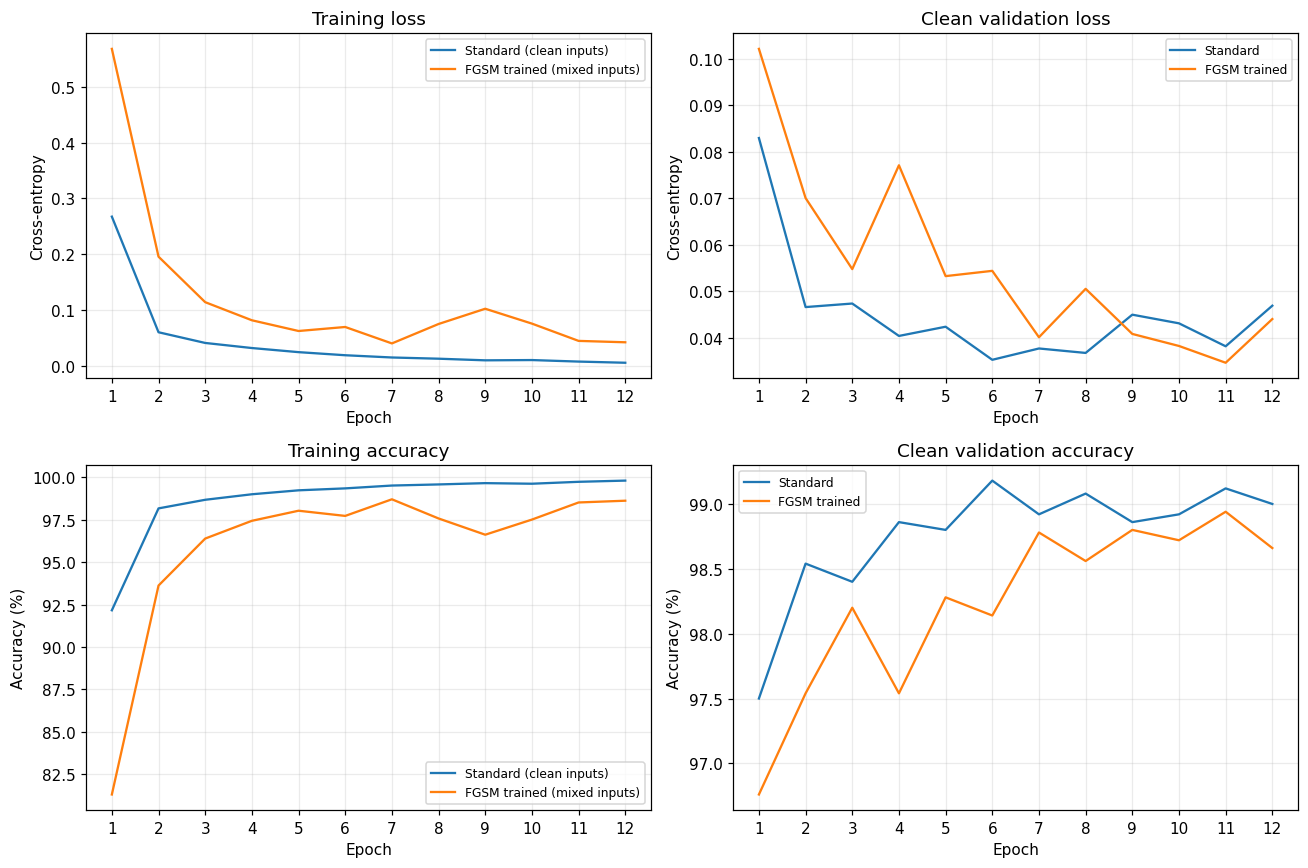

,Model,Training inputs,Final train loss,Final train accuracy (%),Final clean val loss,Final clean val accuracy (%),Training minutes
0,Standard,Clean,0.006,99.815,0.047,99.00,1.703
1,FGSM trained,50/50 mixed,0.042,98.629,0.044,98.66,1.892


In [7]:
# Plot labeled training and clean-validation curves and summarize final epochs.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for name, history in histories.items():
  for row, metric in enumerate(("loss", "accuracy")):
    scale = 100 if metric == "accuracy" else 1
    kind = "mixed" if name == "FGSM trained" else "clean"
    axes[row, 0].plot(history.epoch, scale * history[f"train_{metric}"],
                      label=f"{name} ({kind} inputs)")
    axes[row, 1].plot(history.epoch, scale * history[f"val_{metric}"], label=name)
for ax, title, ylabel in zip(axes.flat,
    ("Training loss", "Clean validation loss", "Training accuracy", "Clean validation accuracy"),
    ("Cross-entropy", "Cross-entropy", "Accuracy (%)", "Accuracy (%)")):
  ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
  ax.set_xticks(range(1, EPOCHS + 1))
  ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
training_summary = pd.DataFrame([
  {"Model": name, "Training inputs": "50/50 mixed" if name == "FGSM trained" else "Clean",
    "Final train loss": h.iloc[-1].train_loss,
    "Final train accuracy (%)": 100 * h.iloc[-1].train_accuracy,
    "Final clean val loss": h.iloc[-1].val_loss,
    "Final clean val accuracy (%)": 100 * h.iloc[-1].val_accuracy,
    "Training minutes": training_seconds[name] / 60}
  for name, h in histories.items()
])
display(training_summary.round(3))

## Training Results and Analysis

The training curves and final summary table illustrate the performance of both CNNs over 12 epochs. We examine their cross-entropy losses, classification accuracies, and training times to understand how FGSM adversarial training affects convergence, clean-image classification, and computational efficiency.

### Training Loss and Accuracy

Both models exhibit substantial improvements during the initial training epochs, although their learning trajectories differ. The **standard CNN** converges relatively quickly, with its training loss decreasing from approximately $0.27$ during the first epoch to $0.006$ by epoch 12. Its final training accuracy reaches $99.815\%$, indicating that the model learns to classify nearly all clean MNIST training examples correctly.

The **FGSM-trained CNN** meanwhile begins with a substantially higher training loss of approximately $0.57$ and lower training accuracy of approximately $81\%$. Although its performance improves considerably, the training loss exhibits noticeable fluctuations, particularly between epochs 6 and 10 (from $0.040$ at epoch 7 to $0.103$ at epoch 9). Because this loss is measured on a mixture whose adversarial half is regenerated against the changing model, the fluctuation is consistent with unstable adversarial training, but it does not by itself identify a cause. By the final epoch, the model achieves a training loss of $0.042$ and training accuracy of $98.629\%$.

These differences are consistent with the additional difficulty introduced by adversarial training. Whereas the standard CNN learns exclusively from clean images, the FGSM-trained CNN must learn from a mixture of clean and adversarially perturbed examples. However, the training metrics are calculated using different input distributions. Therefore, differences in training loss and accuracy should not be interpreted as direct evidence that one model is better at classifying clean images.

### Clean Validation Performance

Unlike the training metrics, validation performance is evaluated using the same 5,000 clean MNIST images for both models, allowing for a direct comparison.

By the end of training, the standard CNN achieves a clean validation accuracy of **99.00%**, while the FGSM-trained CNN achieves **98.66%**. This represents a relatively small difference of $0.34$ percentage points.

Their final clean validation losses are also comparable:

- **Standard CNN:** $0.047$.
- **FGSM-trained CNN:** $0.044$.

The FGSM-trained CNN’s final validation loss $(0.044)$ is slightly lower than the standard CNN’s $(0.047)$, even though its accuracy is slightly lower. These differences are small. With 5,000 validation images, the $0.34$ percentage-point accuracy gap is only about 1.6 standard errors (unpaired), and the standard CNN’s own validation loss ranges from about $0.035$ to $0.047$ over epochs 6–12. I therefore do not treat either difference as meaningful. (Accuracy counts correct predictions while cross-entropy also depends on confidence, so the two metrics can disagree slightly.)

Although the validation curves fluctuate throughout training, both models maintain high clean-image classification accuracy over the later epochs. The FGSM-trained CNN exhibits somewhat greater variability during the earlier stages, but its final performance remains close to the standard CNN.

These results suggest that incorporating FGSM adversarial examples does not substantially reduce clean validation performance under our experimental configuration.

### Computational Cost of Adversarial Training

The summary table also reports the total training time required by each model:

- **Standard CNN:** $1.881$ minutes.
- **FGSM-trained CNN:** $2.084$ minutes.

The FGSM-trained CNN therefore requires approximately $0.203$ additional minutes, an increase of about $10.8\%$ in measured time. Some overhead is expected because each mini-batch requires an extra forward and backward pass on its adversarial half to compute input gradients.

This measurement should be read cautiously. The reported time includes per-epoch validation, and the standard CNN was trained first, so any one-time GPU warm-up cost fell on it, which would slightly understate the overhead. Because only half of each batch is attacked and the network is small, I would not expect this percentage to carry over to larger models, larger images, or iterative attacks such as PGD, which need many gradient evaluations per batch.

Despite this extra computation, the measured training-time difference is relatively modest for our CNN architecture and MNIST dataset.

However, these measurements describe the computational cost under our specific experimental configuration. Larger architectures, higher-resolution datasets, or more computationally demanding adversarial attacks may produce substantially different training-time overhead.

### Interpretation of the Training Results
Our findings reveal three important observations:

1. **Both training procedures achieve strong clean-image performance.** The standard CNN reaches $99.00\%$ clean validation accuracy, while the FGSM-trained CNN reaches $98.66\%$.

2. **Adversarial training introduces additional optimization difficulty.** The FGSM-trained CNN exhibits higher training loss and greater fluctuations, although its mixed-input training metrics are not directly comparable to the clean-input training metrics of the standard CNN.

3. **FGSM adversarial training introduces a measurable computational cost.** On this setup, the FGSM-trained model takes approximately $10.8\%$ longer to train (the measurement includes validation time), reflecting the extra gradient calculations needed to generate adversarial examples.

Overall, the results indicate that FGSM adversarial training can maintain competitive clean-image classification performance while introducing a relatively modest computational overhead in this experiment.

Nevertheless, these results do not establish that the FGSM-trained CNN is more robust against adversarial attacks. Clean validation accuracy measures performance on unmodified images and does not reveal how the models respond to deliberately constructed perturbations.

The next stage of our investigation will therefore evaluate both CNNs against FGSM and PGD attacks across different perturbation magnitudes. This will allow us to determine whether the additional computational cost of FGSM adversarial training produces meaningful improvements in adversarial robustness, particularly against attacks that differ from the one used during training.



## FGSM Robustness Experiment

Having established the training performance of both CNNs, we'll now investigate how well they withstand adversarial perturbations generated using the Fast Gradient Sign Method (FGSM).

Although both models achieved approximately $99\%$ accuracy on clean validation images, this does not necessarily imply that their predictions are resistant to small, deliberately constructed changes in the input. Our objective is to determine how classification accuracy changes as the magnitude of adversarial perturbations increases, and whether FGSM adversarial training provides a measurable improvement over standard training.

### Experimental Setup

For this experiment, we'll use the **official MNIST test set**, consisting of 10,000 images that were not used during training or validation. The test set is loaded only after both CNNs have completed training, preserving its role as an independent evaluation dataset.

Each model will be attacked using its own input gradients. This is known as a **white-box attack**, since the attack uses information about the model's parameters and loss function to construct adversarial examples. For an input image $x$ with true label $y$, FGSM generates an adversarial example according to

$$
x_{\mathrm{adv}}
=
\operatorname{clip}_{[0,1]}
\left(
x+\epsilon\operatorname{sign}
\left(\nabla_x J(\theta,x,y)\right)
\right).
$$

Here, $\epsilon$ controls the maximum permitted change to each pixel. By evaluating the models across different values of $\epsilon$, we can investigate how their classification performance changes as the attack becomes more aggressive.

The primary evaluation will use all 10,000 test images, including those that were incorrectly classified before any perturbation was applied. Thus, adversarial accuracy is defined as

$$
A_{\mathrm{adv}}(\epsilon)
=
\frac{1}{N}
\sum_{i=1}^{N}
\mathbf{1}
\left[
f_\theta(x_i^{\mathrm{adv}})=y_i
\right],
$$

where $N=10{,}000$ and $\mathbf{1}[\cdot]$ is the indicator function, equal to 1 when the prediction is correct and 0 otherwise. This definition allows us to compare adversarial accuracy directly against clean test accuracy, rather than measuring attack success only among images that were originally classified correctly.

### Preparing for FGSM and PGD Comparisons

In addition to evaluating FGSM on the complete test set, we'll reserve a **fixed random subset of 1,000 test images** for a subsequent comparison between FGSM and Projected Gradient Descent (PGD).

Using the same subset for both attacks and both models ensures that differences in their measured performance are not caused by evaluating different images. The original test indices are retained to preserve the identity of the selected samples.

All evaluation data loaders preserve the established sample order and include incomplete final mini-batches, ensuring that no test examples are unintentionally omitted.

### Implementation Verification

Before interpreting the attack results, we'll perform several checks to verify that the implementation behaves as expected:

- **Input dimensions and pixel bounds:** Confirm that adversarial images retain the expected shapes and remain within $[0,1]$.
- **Perturbation constraints:** Verify that the maximum absolute pixel perturbation satisfies the specified $L_\infty$ budget.
- **Zero-perturbation behavior:** Confirm that setting $\epsilon=0$ returns the original images.
- **Gradient isolation:** Verify that generating attacks does not modify existing model-parameter gradients.
- **Model mode restoration:** Confirm that the attack functions restore the model's original training or evaluation mode.
- **Dataset integrity:** Verify that the training, validation, and test partitions remain separate and that the selected evaluation subset is valid.

These checks are executed when the notebook runs and help establish that our reported results reflect the intended attack procedures rather than implementation errors.

In [8]:
# Construct final-evaluation loaders and verify attack behavior without model updates.
test_source = datasets.MNIST(
  root=str(DATA_ROOT), train=False, transform=transforms.ToTensor(), download=True
)
assert train_source.train is True and test_source.train is False
assert train_data.dataset is train_source and val_data.dataset is train_source
assert len(test_source) == 10000
subset_indices = torch.randperm(10000, generator=torch.Generator().manual_seed(SEED))[:1000].tolist()
assert len(set(subset_indices)) == 1000
assert all(0 <= i < 10000 for i in subset_indices)
test_subset = Subset(test_source, subset_indices)
full_test_loader = make_loader(test_source)
subset_loader = make_loader(test_subset)
assert subset_loader.dataset is test_subset
assert subset_loader.dataset.indices == subset_indices

probe_x, probe_y = next(iter(val_loader))
probe_x, probe_y = probe_x[:8].to(device), probe_y[:8].to(device)
for model in models.values():
  model.eval()
  saved_parameters = [p.detach().clone() for p in model.parameters()]
  # Nonzero sentinels verify attacks preserve existing gradients as well as values.
  for p in model.parameters():
    assert p.grad is None
    p.grad = torch.ones_like(p)
  for epsilon in (0.0, EPS_TRAIN):
    for attack in (fgsm, pgd):
      attacked = attack(model, probe_x, probe_y, epsilon)
      check_images(probe_x, attacked, epsilon)
      assert not attacked.requires_grad and not model.training
      assert model(attacked).shape == (len(probe_y), 10)
      assert all(torch.equal(p.grad, torch.ones_like(p)) for p in model.parameters())
  assert all(torch.equal(p, old) for p, old in zip(model.parameters(), saved_parameters))
  for p in model.parameters():
    p.grad = None
  model.train()
  fgsm(model, probe_x, probe_y, EPS_TRAIN)
  assert model.training
  assert all(p.grad is None for p in model.parameters())
  model.eval()
print("Partition, shape, constraint, zero-attack, and gradient checks passed.")

Partition, shape, constraint, zero-attack, and gradient checks passed.


With the evaluation setup established, we'll examine how both CNNs respond to increasing FGSM perturbation magnitudes and determine whether the robustness gained through FGSM adversarial training extends beyond clean-image classification performance.

Full-test FGSM accuracy (%),Standard,FGSM trained
Epsilon,,
0.00,98.93,98.81
0.05,95.06,96.73
0.10,83.60,95.77
0.15,63.34,98.26
0.20,44.43,98.97
0.25,30.79,97.84
0.30,21.44,93.55


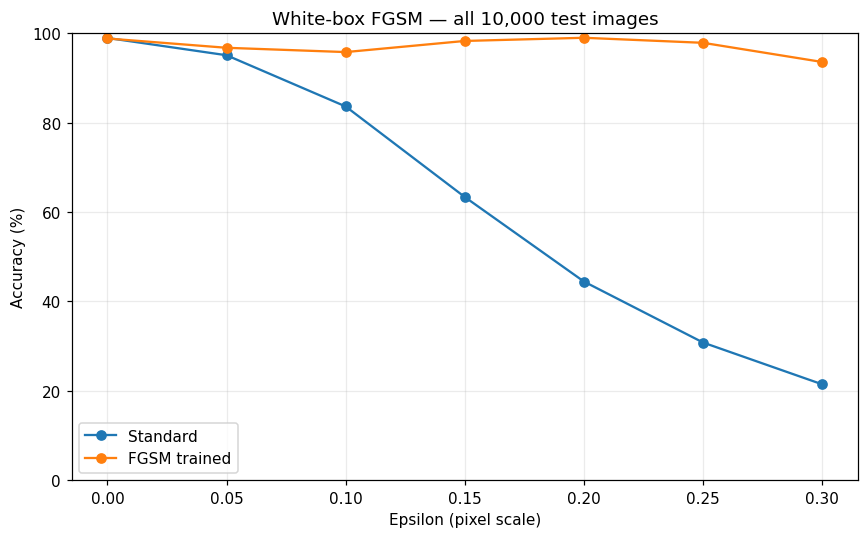

In [9]:
# Evaluate white-box attacks while retaining ordered per-image predictions.
def evaluate_attack(model, loader, attack, epsilon):
  model.eval()
  predictions, labels = [], []
  # Reset for every call: matched random starts across models at each epsilon.
  generator = torch.Generator(device=device).manual_seed(SEED)
  for x, y in loader:
    x, y = x.to(device), y.to(device)
    if attack == "FGSM":
      attacked = fgsm(model, x, y, epsilon)
    elif attack == "PGD":
      attacked = pgd(model, x, y, epsilon, generator=generator)
    else:
      raise ValueError("Unknown attack")
    check_images(x, attacked, epsilon)
    with torch.no_grad():
      logits = model(attacked)
      assert logits.shape == (len(y), 10)
      predictions.append(logits.argmax(1).cpu())
      labels.append(y.cpu())
  predictions, labels = torch.cat(predictions), torch.cat(labels)
  assert len(labels) == len(loader.dataset)
  return {"predictions": predictions, "labels": labels,
          "accuracy": (predictions == labels).float().mean().item(), "n": len(labels)}

full_fgsm, clean_full = {}, {}
for name, model in models.items():
  clean_full[name] = evaluate_clean(model, full_test_loader)
  for epsilon in EPSILONS:
    result = evaluate_attack(model, full_test_loader, "FGSM", epsilon)
    assert torch.equal(result["labels"], test_source.targets)
    if epsilon == 0:
      assert abs(result["accuracy"] - clean_full[name]["accuracy"]) < TOL
    full_fgsm[name, epsilon] = result
fgsm_table = pd.DataFrame({
  name: [100 * full_fgsm[name, e]["accuracy"] for e in EPSILONS]
  for name in models
}, index=pd.Index(EPSILONS, name="Epsilon"))
display(fgsm_table.round(2).rename_axis(columns="Full-test FGSM accuracy (%)"))
ax = fgsm_table.plot(marker="o", figsize=(8, 5))
ax.set(title="White-box FGSM — all 10,000 test images", xlabel="Epsilon (pixel scale)",
        ylabel="Accuracy (%)", ylim=(0, 100))
plt.tight_layout()
plt.show()


## FGSM Robustness Results and Analysis

The table and graph above illustrate how classification accuracy changes as the FGSM perturbation magnitude $\epsilon$ increases from $0$ to $0.30$. Both CNNs are evaluated on the complete set of 10,000 MNIST test images, with each model subjected to a white-box FGSM attack generated using its own input gradients.

### Standard CNN Performance

The standard CNN demonstrates a substantial decline in classification accuracy as the perturbation magnitude increases.

At $\epsilon = 0$, corresponding to unmodified test images, the model achieves an accuracy of **98.93%**. However, even relatively small perturbations begin to affect its predictions:

- At $\epsilon = 0.05$, accuracy decreases to $95.06\%$.
- At $\epsilon = 0.10$, accuracy falls to $83.60\%$.
- At $\epsilon = 0.20$, accuracy drops to $44.43\%$.
- At $\epsilon = 0.30$, accuracy reaches only $21.44\%$.

Between $\epsilon = 0$ and $\epsilon = 0.30$, the standard CNN experiences a decline of **77.49 percentage points** in classification accuracy.

These results demonstrate that high accuracy on clean test images does not necessarily imply robustness to adversarial perturbations. Although the standard CNN correctly classifies nearly all unmodified MNIST images, its predictions become increasingly vulnerable as FGSM is permitted to modify pixel intensities more substantially.

### FGSM-Trained CNN Performance

In contrast, the FGSM-trained CNN's accuracy under the same attack stays far higher. At $\epsilon = 0$, the model achieves **98.81%** accuracy, only $0.12$ percentage points below the standard CNN. However, its accuracy remains substantially higher as the perturbation magnitude increases.

At the training perturbation budget of $\epsilon = 0.20$, the FGSM-trained CNN maintains **98.97%** accuracy, compared with only $44.43\%$ for the standard CNN. This is a difference of 54.54 percentage points under FGSM evaluation.

Even at $\epsilon = 0.30$, which exceeds the perturbation magnitude used during adversarial training, the FGSM-trained CNN retains **93.55%** accuracy.

Its accuracy under FGSM does not decrease monotonically as $\epsilon$ increases. It rises from $95.77\%$ at $\epsilon=0.10$ to $98.26\%$ at $\epsilon=0.15$ and $98.97\%$ at $\epsilon=0.20$, where it is slightly above the model’s clean test accuracy of $98.81\%$ (a $0.16$ percentage-point difference, within sampling noise).

These two facts matter mathematically, not just empirically. Let $R(\epsilon)$ denote the true worst-case accuracy over the permitted region $\mathcal{B}_\epsilon(x)\cap[0,1]^d$. Because $\delta=0$ is always permitted, $R(\epsilon)$ cannot exceed clean accuracy. Because the regions are nested as $\epsilon$ grows, $R(\epsilon)$ cannot increase with $\epsilon$. Any attack’s accuracy is an upper bound on $R(\epsilon)$, since each adversarial example it finds certifies a failure. The FGSM accuracy curve for this model increases with $\epsilon$ and, at $\epsilon=0.20$, slightly exceeds clean accuracy, so it cannot be measuring the model’s true worst-case accuracy. FGSM is failing to find damaging perturbations against this model at these budgets.

### Interpretation and Limitations

The FGSM results show that accuracy under FGSM rises to near the clean level after FGSM adversarial training. By themselves they do not show that the model has become more robust; they show that FGSM has become a weak attack against it. High accuracy under an attack is evidence of robustness only if the attack is strong, and the pattern above indicates it is not strong here.

This is why resistance to a particular attack must be distinguished from adversarial robustness more generally. Several mechanisms could produce this pattern, and this experiment cannot separate them. Single-step adversarial training can produce loss surfaces on which a one-step attack is ineffective (gradient masking), or can lose robustness to iterative attacks abruptly while keeping high accuracy against the training attack (catastrophic overfitting). A third candidate is label leaking: FGSM perturbations are computed from the true label, so a model trained on them can learn to read label information from the perturbation itself, which tends to push accuracy on adversarial inputs up to or above clean accuracy. All three are hypotheses here; none is established by this experiment.

A more demanding evaluation is therefore required before drawing conclusions about the model’s broader adversarial robustness. For this reason, we’ll subsequently compare FGSM against the iterative PGD attack, which performs multiple gradient-based updates while remaining within the same perturbation constraints.


### Visualizing Adversarial Perturbations

Before proceeding to PGD, we'll examine several individual examples to better understand how FGSM modifies MNIST images and influences the predictions of each CNN.

The following visualization uses a fixed selection of test images rather than choosing examples based on whether an attack succeeds or fails. For each example, we'll display:

1. **The original image**, showing the unmodified handwritten digit.
2. **The perturbation**, illustrating the pixel-level changes introduced by FGSM.
3. **The adversarial image**, showing the resulting input after applying the perturbation and enforcing the valid pixel range.

These examples use $\epsilon = 0.20$, matching the perturbation magnitude used during FGSM adversarial training.

By comparing the original images, perturbation patterns, and resulting predictions, we can examine how the same attack procedure affects the standard and FGSM-trained CNNs.

The perturbation panels use a fixed color range of $\pm0.20$, which equals the actual perturbation budget, so the colors reflect the true pixel changes. On black background pixels, negative changes are clipped back to $0$ by the valid-range constraint, so the effective perturbation there is either positive or zero. At $\epsilon=0.20$ the resulting gray background noise is visible to the eye, which is worth keeping in mind given that adversarial examples are often described as looking similar to the originals.

This qualitative examination complements the full-test accuracy results by illustrating how gradient-based perturbations can influence individual predictions, while the subsequent PGD experiment will provide a stronger quantitative test of adversarial robustness.


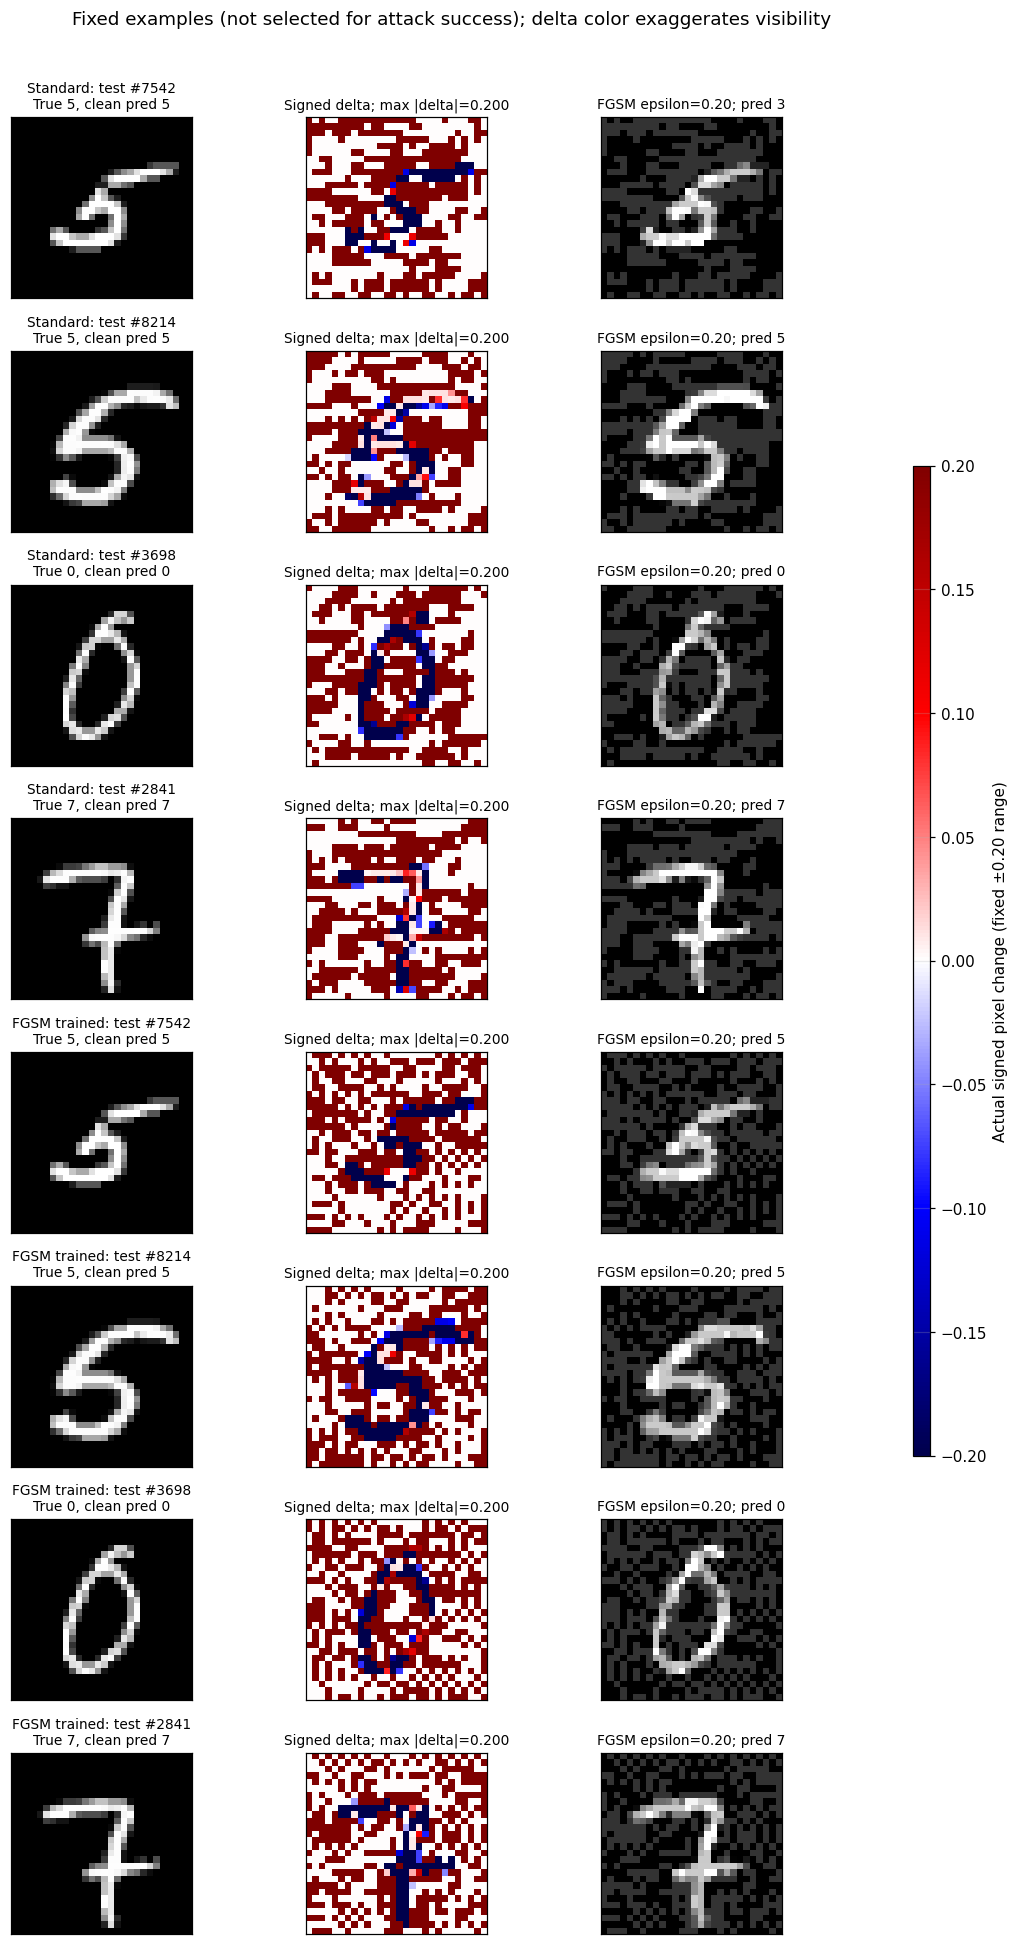

In [10]:
# Display predetermined test examples with signed perturbations on a fixed scale.
example_indices = subset_indices[:4]  # Chosen before inspecting predictions.
example_x = torch.stack([test_source[i][0] for i in example_indices]).to(device)
example_y = torch.tensor([test_source[i][1] for i in example_indices], device=device)
fig, axes = plt.subplots(2 * len(example_indices), 3, figsize=(10, 18))
for model_number, (name, model) in enumerate(models.items()):
  adversarial = fgsm(model, example_x, example_y, EPS_TRAIN)
  check_images(example_x, adversarial, EPS_TRAIN)
  with torch.no_grad():
    clean_predictions = model(example_x).argmax(1).cpu().tolist()
    adv_predictions = model(adversarial).argmax(1).cpu().tolist()
  for j, test_index in enumerate(example_indices):
    row = model_number * len(example_indices) + j
    delta = (adversarial[j] - example_x[j]).detach().cpu().squeeze()
    axes[row, 0].imshow(example_x[j].cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"{name}: test #{test_index}\nTrue {example_y[j].item()}, clean pred {clean_predictions[j]}", fontsize=9)
    perturbation = axes[row, 1].imshow(delta, cmap="seismic", vmin=-EPS_TRAIN, vmax=EPS_TRAIN)
    axes[row, 1].set_title(f"Signed delta; max |delta|={delta.abs().max():.3f}", fontsize=9)
    axes[row, 2].imshow(adversarial[j].cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title(f"FGSM epsilon={EPS_TRAIN:.2f}; pred {adv_predictions[j]}", fontsize=9)
    for ax in axes[row]:
      ax.set_xticks([])
      ax.set_yticks([])
fig.suptitle("Fixed examples (not selected for attack success); delta color exaggerates visibility")
fig.tight_layout(rect=(0, 0, 0.9, 0.97))
cbar_ax = fig.add_axes([0.92, 0.25, 0.015, 0.5])
fig.colorbar(perturbation, cax=cbar_ax, label="Actual signed pixel change (fixed ±0.20 range)")
plt.show()

For the **standard CNN**, the first handwritten digit 5 is correctly classified before the attack but misclassified as 3 after FGSM is applied. This illustrates how a gradient-based perturbation can change a model's prediction even when the underlying digit remains visually recognizable.

However, the remaining three examples retain their correct predictions after perturbation. This is an important reminder that FGSM does not necessarily cause every image to be misclassified, even at a relatively large perturbation magnitude.

For the **FGSM-trained CNN**, all four examples retain their correct predictions after the attack. In particular, the first digit 5 remains correctly classified, unlike its corresponding result from the standard CNN.

Another notable observation is that the perturbation patterns differ between the two models, despite using the same original images and perturbation budget.

This occurs because FGSM constructs its perturbations using the gradient of each model's own loss function:

$$
\delta = \epsilon \operatorname{sign}(\nabla_x J(\theta,x,y)).
$$

Since the two CNNs have learned different parameters through their respective training procedures, their input gradients can point in different directions. Consequently, the adversarial perturbations generated for one model are not necessarily identical to those generated for the other. Qualitatively, in these four examples the standard CNN’s perturbation forms larger contiguous blocks, whereas the FGSM-trained CNN’s background perturbation looks finer and more checkerboard-like. This is an observation from four images only. I did not quantify it, and it should not be taken as evidence for any specific mechanism.

### Interpretation and Limitations

These examples are consistent with the earlier quantitative observation that FGSM is less effective against the FGSM-trained CNN. Nevertheless, the visualization should be interpreted carefully. The four test images were fixed rather than selected according to attack success, and they represent only a small portion of the complete test dataset. Therefore, the examples are intended to illustrate how FGSM modifies individual images and affects model predictions, rather than establish an independent measure of adversarial robustness.

The full-test results provide stronger quantitative evidence: at $\epsilon = 0.20$, the standard CNN achieves $44.43\%$ accuracy, whereas the FGSM-trained CNN achieves $98.97\%$. However, the unusually high FGSM accuracy of the adversarially trained model raises an important question: **has the model learned to resist adversarial perturbations more generally, or has FGSM simply become ineffective against it?**


## PGD Robustness Experiment

Having examined the effects of single-step FGSM attacks, we'll now evaluate both CNNs using **Projected Gradient Descent (PGD)**, a stronger iterative adversarial attack.

Although our previous experiment demonstrated that FGSM adversarial training substantially improves resistance to FGSM-generated perturbations, this does not necessarily indicate that the model has learned to withstand adversarial attacks more generally.

Our objective is to investigate whether the FGSM-trained CNN maintains its robustness when subjected to an attack that performs multiple gradient-based updates instead of a single perturbation.

### Experimental Setup

For this experiment, we'll use the **fixed subset of 1,000 MNIST test images** established during the FGSM evaluation. Both CNNs will be evaluated on the same images, using the same perturbation magnitudes as before.

We configure PGD using the following parameters:

| Parameter | Configuration |
|---|---|
| Evaluation images | 1,000 fixed MNIST test images |
| PGD iterations | 10 |
| Random starts | 1 |
| Step size | $\alpha = \epsilon/4$ |
| Perturbation constraint | $L_\infty$ |
| Pixel intensity bounds | $[0,1]$ |
| Attack objective | Maximize cross-entropy loss |

Unlike FGSM, which generates an adversarial example in a single step, PGD repeatedly modifies the input image using the gradient of the classification loss.

For each iteration, the adversarial input is updated according to

$$
x_{k+1}
=
\Pi_{\mathcal{B}_\epsilon(x)\cap[0,1]^d}
\left(
x_k
+
\alpha\operatorname{sign}
\left(
\nabla_x J(\theta,x_k,y)
\right)
\right),
$$

where $\Pi$ represents projection onto the feasible perturbation region, $\mathcal{B}_\epsilon(x)$ is the $L_\infty$ neighborhood around the original image, and $\alpha$ determines the size of each update.

We set $\alpha = \epsilon/4$, allowing the attack to make several updates within the permitted region. After each iteration, the resulting image is projected back into the allowed neighborhood and clipped to the valid pixel range.

### Random Initialization and Candidate Selection

Rather than beginning every attack at the original image, PGD uses a **random initialization** within the permitted perturbation region:

$$
x_0
=
\operatorname{clip}_{[0,1]}(x+\delta),
\qquad
\delta_i\sim\mathcal{U}(-\epsilon,\epsilon).
$$

Here, each component of $\delta$ is sampled uniformly from the interval $[-\epsilon,\epsilon]$ before pixel clipping.

This random initialization allows PGD to begin exploring the loss landscape from a point other than the original input. However, our implementation uses only one random start per image, so it does not explore every possible initialization.

An additional feature of our implementation is that we retain the **highest-cross-entropy candidate** encountered during the attack.

For each image, we compare the classification loss obtained from:

1. The original clean image.
2. The randomly initialized image.
3. Each of the ten PGD iterations.

The candidate producing the highest cross-entropy loss is selected as the final adversarial example.

This prevents the attack from discarding an earlier perturbation that produces a larger loss than the final iteration. However, maximizing cross-entropy loss does not always correspond exactly to maximizing the number of classification errors, since a higher loss does not necessarily imply an incorrect predicted class.

### Comparison Against FGSM

To ensure a consistent comparison, we'll also recompute FGSM accuracy using the **same ordered subset of 1,000 test images**. This is important because our earlier FGSM experiment evaluated all 10,000 test images, whereas PGD is computationally more expensive due to its repeated gradient calculations. By evaluating FGSM and PGD on the same subset, we can compare their effectiveness without introducing differences caused by the selection of evaluation images.

As before, adversarial accuracy is calculated over every image in the evaluation subset, including images that were already misclassified before the attack. Therefore, the reported results measure overall classification accuracy under attack, rather than attack success conditional on initially correct predictions.

### Limitations of the PGD Evaluation

Although PGD is generally a stronger attack than FGSM because it uses multiple gradient-based updates, our evaluation is still subject to a finite computational budget.

In particular, we'll use **10 iterations and one random start** for each perturbation magnitude. Increasing the number of iterations or random restarts could potentially identify adversarial examples that this configuration misses.

Furthermore, the reported accuracies are empirical measurements under the specified attacks. They should not be interpreted as **certified robustness guarantees**, which would require establishing that no permitted perturbation can change a model's prediction.

Two further details affect how the numbers should be read. First, the attack keeps the iterate with the highest cross-entropy loss rather than any iterate that is misclassified, so an iterate that fools the model can be discarded in favor of a higher-loss iterate that is still classified correctly. The reported PGD accuracies are therefore upper bounds that may be slightly higher than an attack tracking misclassification would give. This makes the attack, if anything, weaker, so it does not threaten the near-zero accuracies reported below. Second, the 1,000-image subset is a design choice to limit computation, and it adds sampling uncertainty (a standard error of up to about $1.6$ percentage points when accuracy is near $50\%$, and about $0.3$ percentage points near $99\%$).

With these considerations established, we'll compare how both CNNs perform under FGSM and PGD across the same perturbation magnitudes. This will help us determine whether the apparent robustness gained through FGSM adversarial training extends to a stronger iterative attack.


Standard, epsilon=0.00: 0 mismatches
Standard, epsilon=0.05: 0 mismatches
Standard, epsilon=0.10: 0 mismatches
Standard, epsilon=0.15: 2 mismatches
Standard, epsilon=0.20: 4 mismatches
Standard, epsilon=0.25: 2 mismatches
Standard, epsilon=0.30: 6 mismatches
FGSM trained, epsilon=0.00: 0 mismatches
FGSM trained, epsilon=0.05: 0 mismatches
FGSM trained, epsilon=0.10: 0 mismatches
FGSM trained, epsilon=0.15: 0 mismatches
FGSM trained, epsilon=0.20: 0 mismatches
FGSM trained, epsilon=0.25: 0 mismatches
FGSM trained, epsilon=0.30: 0 mismatches


Matched-subset PGD accuracy (%),Standard,FGSM trained
Epsilon,,
0.00,99.3,99.1
0.05,94.3,89.1
0.10,72.3,53.7
0.15,19.6,0.7
0.20,1.4,0.0
0.25,0.0,0.0
0.30,0.0,0.0


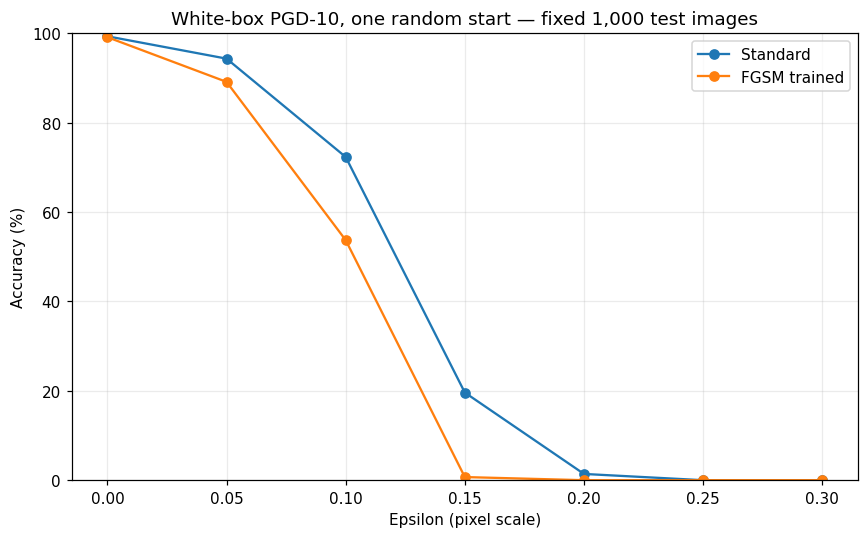

In [11]:
# Evaluate matched-subset FGSM and PGD and verify all zero-epsilon predictions.
matched, clean_subset = {}, {}
expected_labels = test_source.targets[torch.tensor(subset_indices)]

for name, model in models.items():
  clean_subset[name] = evaluate_clean(model, subset_loader)

  for epsilon in EPSILONS:
    for attack in ("FGSM", "PGD"):
      result = evaluate_attack(model, subset_loader, attack, epsilon)
      assert result["n"] == 1000
      assert torch.equal(result["labels"], expected_labels)

      if epsilon == 0:
        assert abs(result["accuracy"] - clean_subset[name]["accuracy"]) < TOL
        assert torch.equal(
          result["predictions"],
          full_fgsm[name, 0.0]["predictions"][subset_indices]
        )

      matched[name, attack, epsilon] = result

  # Diagnostic: compare subset FGSM predictions against full-test FGSM.
  for epsilon in EPSILONS:
    subset_predictions = matched[name, "FGSM", epsilon]["predictions"]
    full_predictions = full_fgsm[name, epsilon]["predictions"][subset_indices]

    mismatches = (subset_predictions != full_predictions).sum().item()
    print(f"{name}, epsilon={epsilon:.2f}: {mismatches} mismatches")

pgd_table = pd.DataFrame({
  name: [100 * matched[name, "PGD", e]["accuracy"] for e in EPSILONS]
  for name in models
}, index=pd.Index(EPSILONS, name="Epsilon"))

display(pgd_table.round(2).rename_axis(columns="Matched-subset PGD accuracy (%)"))

ax = pgd_table.plot(marker="o", figsize=(8, 5))
ax.set(
  title="White-box PGD-10, one random start — fixed 1,000 test images",
  xlabel="Epsilon (pixel scale)",
  ylabel="Accuracy (%)",
  ylim=(0, 100)
)
plt.tight_layout()
plt.show()


## Comparative Results

### PGD Robustness Analysis

The PGD results reveal a substantial decline in classification accuracy for both CNNs as the perturbation magnitude increases. However, unlike our earlier FGSM experiment, the **standard CNN consistently outperforms the FGSM-trained CNN** at perturbation magnitudes where their accuracies differ.

At $\epsilon = 0.10$, the standard CNN achieves $72.3\%$ accuracy, compared with $53.7\%$ for the FGSM-trained CNN. This difference becomes particularly pronounced at $\epsilon = 0.15$, where their accuracies decrease to $19.6\%$ and $0.7\%$, respectively.

By $\epsilon = 0.20$, the standard CNN retains only $1.4\%$ accuracy, while the FGSM-trained CNN falls to $0.0\%$. Both models reach $0.0\%$ accuracy at $\epsilon = 0.25$ and $0.30$.

These findings suggest that **FGSM adversarial training does not improve resistance to PGD under our experimental configuration**. In fact, the FGSM-trained model is more vulnerable to PGD across several perturbation magnitudes, despite its much higher accuracy under FGSM in the previous experiment.

Sampling noise does not explain these gaps. With 1,000 images, the PGD accuracy gaps at $\epsilon=0.05$, $0.10$, and $0.15$ ($5.2$, $18.6$, and $18.9$ percentage points) are roughly 4, 9, and 15 unpaired standard errors. The gap at $\epsilon=0.20$ ($1.4\%$ versus $0.0\%$, about 14 images) is small in absolute terms. However, these are single-run results, and sampling error on the test images does not capture variability across training runs.

One detail about the matched subset: for the standard CNN, FGSM predictions on the subset differ from those on the full test set for $2$, $4$, $2$, and $6$ images at $\epsilon=0.15$, $0.20$, $0.25$, and $0.30$, and for none at smaller $\epsilon$. The FGSM-trained CNN shows no mismatches. FGSM is deterministic given the model and input, so these are probably small floating-point differences caused by different batch composition, which I did not verify. They do not change any conclusion, but they mean matched-subset FGSM accuracies can differ slightly from full-test values.

### Comparing FGSM and PGD

This contrasting behavior motivates a direct comparison between the two attacks.

The following tables and figures compare FGSM and PGD accuracy using the same fixed subset of 1,000 MNIST test images. In particular, we'll examine the difference

$$
\Delta A(\epsilon)
=
A_{\mathrm{FGSM}}(\epsilon)
-
A_{\mathrm{PGD}}(\epsilon),
$$

where a positive value indicates higher classification accuracy under FGSM than under PGD.

Our goal is to determine how much the effectiveness of each attack differs between the two training procedures, and whether the apparent robustness gained through FGSM adversarial training extends beyond the attack used during training.



,Model,Epsilon,N,FGSM accuracy (%),PGD accuracy (%),FGSM minus PGD (pp)
0,Standard,0.00,1000,99.3,99.3,0.0
1,Standard,0.05,1000,95.8,94.3,1.5
2,Standard,0.10,1000,84.8,72.3,12.5
3,Standard,0.15,1000,63.8,19.6,44.2
4,Standard,0.20,1000,44.6,1.4,43.2
5,Standard,0.25,1000,30.2,0.0,30.2
6,Standard,0.30,1000,20.6,0.0,20.6
7,FGSM trained,0.00,1000,99.1,99.1,0.0
8,FGSM trained,0.05,1000,97.3,89.1,8.2
9,FGSM trained,0.10,1000,95.7,53.7,42.0


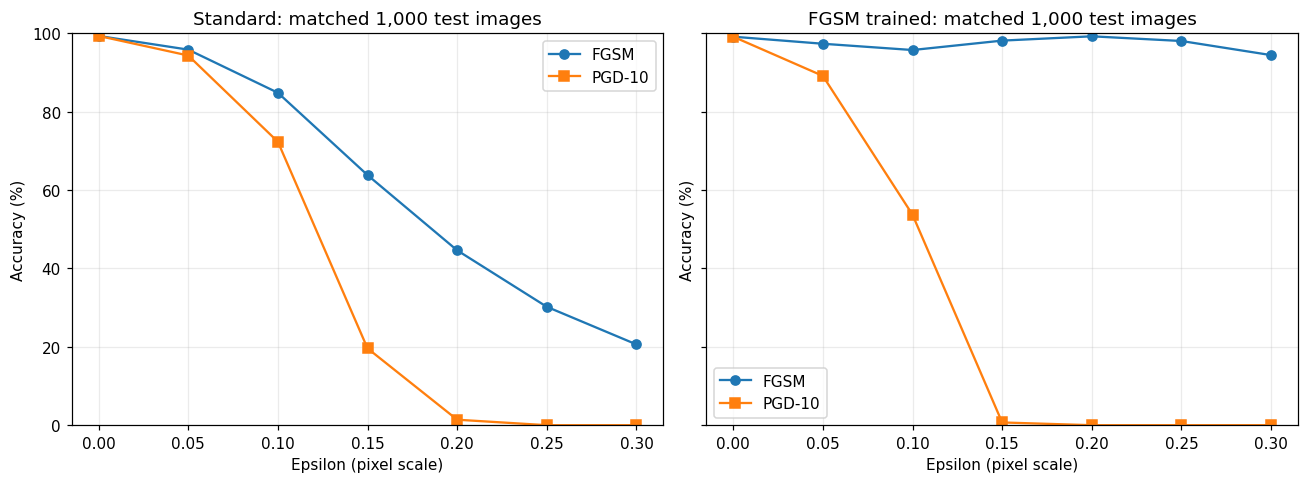

In [12]:
# Tabulate matched attack accuracies and the FGSM–PGD gap at every epsilon.
comparison = pd.DataFrame([
  {"Model": name, "Epsilon": e, "N": 1000,
    "FGSM accuracy (%)": 100 * matched[name, "FGSM", e]["accuracy"],
    "PGD accuracy (%)": 100 * matched[name, "PGD", e]["accuracy"],
    "FGSM minus PGD (pp)": 100 * (matched[name, "FGSM", e]["accuracy"]
                                    - matched[name, "PGD", e]["accuracy"])}
  for name in models for e in EPSILONS
])
display(comparison.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, name in zip(axes, models):
  rows = comparison[comparison.Model == name]
  ax.plot(rows.Epsilon, rows["FGSM accuracy (%)"], marker="o", label="FGSM")
  ax.plot(rows.Epsilon, rows["PGD accuracy (%)"], marker="s", label="PGD-10")
  ax.set(title=f"{name}: matched 1,000 test images", xlabel="Epsilon (pixel scale)",
          ylabel="Accuracy (%)", ylim=(0, 100))
  ax.legend()
fig.tight_layout()
plt.show()

### FGSM vs. PGD: Comparative Analysis

The comparison reveals a substantial difference in how the standard CNN and FGSM-trained CNN respond to single-step and iterative adversarial attacks.

**Standard CNN**

For the standard CNN, both FGSM and PGD become increasingly effective as the perturbation magnitude increases. However, PGD consistently produces lower classification accuracy than FGSM at nonzero values of $\epsilon$ where the results differ. At $\epsilon = 0.10$, the standard CNN achieves $84.8\%$ accuracy under FGSM, compared with $72.3\%$ under PGD. This difference grows to **44.2 percentage points** at $\epsilon = 0.15$, before reaching 43.2 percentage points at $\epsilon = 0.20$. These results indicate that the iterative updates performed by PGD identify more damaging perturbations than the single-step FGSM attack under the tested configurations.

**FGSM-Trained CNN**

The FGSM-trained CNN exhibits a considerably different pattern. Its accuracy under FGSM remains above $94\%$ across all tested perturbation magnitudes, indicating that FGSM is largely ineffective against it. However, its performance under PGD deteriorates rapidly. At $\epsilon = 0.10$, FGSM accuracy remains at $95.7\%$, while PGD accuracy decreases to $53.7\%$. By $\epsilon = 0.15$, these values diverge to $98.1\%$ and $0.7\%$, respectively. The largest difference occurs at the training perturbation budget of $\epsilon = 0.20$, where FGSM accuracy reaches **99.2%**, while PGD accuracy falls to **0.0%**. This produces an accuracy gap of **99.2 percentage points**.

### Interpretation

These findings suggest that, after FGSM adversarial training, FGSM becomes a much weaker attack against the model (its FGSM accuracy rises to near clean accuracy), and that this does not reflect resistance to PGD under our experimental conditions. The becomes particularly striking because the FGSM-trained CNN maintains high accuracy against FGSM even at larger perturbation magnitudes, while the iterative PGD attack reduces its accuracy to nearly zero at much smaller values of $\epsilon$. This behavior raises the possibility that the model has adapted to the specific perturbations generated by FGSM rather than learning broader adversarial robustness. However, the observed accuracy gap alone does not establish the underlying mechanism. Further investigation would be needed to determine whether phenomena such as gradient masking, catastrophic overfitting, or label leaking contribute to this behavior. Overall, the comparison demonstrates that **robustness against a particular adversarial attack should not be treated as evidence of robustness against other attacks**, even when they operate under the same perturbation constraints.


,N,Clean (%),FGSM (%),PGD-10 (%)
Model,,,,
Standard,1000,99.3,44.6,1.4
FGSM trained,1000,99.1,99.2,0.0


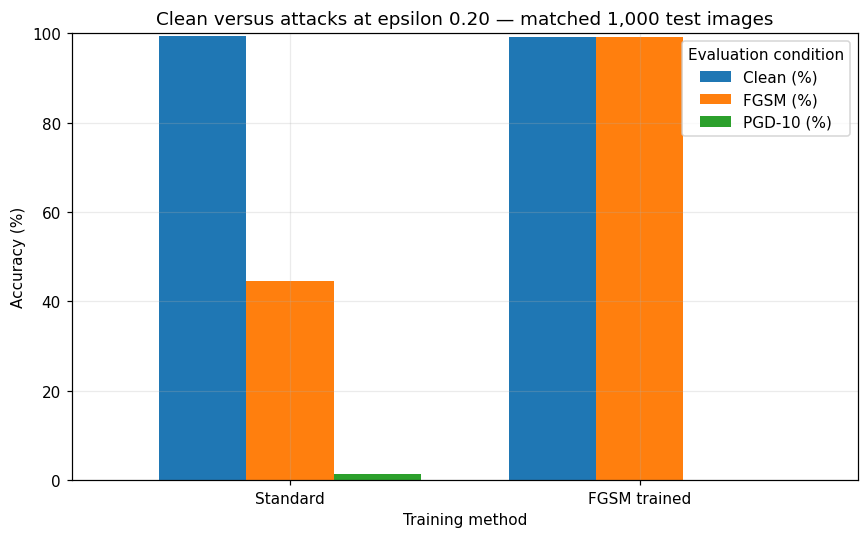

Measured total training time: 3.60 minutes


In [13]:
# Compare clean and attacked accuracy at the prespecified training epsilon.
summary_020 = pd.DataFrame([
  {"Model": name, "N": 1000,
    "Clean (%)": 100 * clean_subset[name]["accuracy"],
    "FGSM (%)": 100 * matched[name, "FGSM", EPS_TRAIN]["accuracy"],
    "PGD-10 (%)": 100 * matched[name, "PGD", EPS_TRAIN]["accuracy"]}
  for name in models
]).set_index("Model")
display(summary_020.round(2))
ax = summary_020[["Clean (%)", "FGSM (%)", "PGD-10 (%)"]].plot.bar(
  figsize=(8, 5), rot=0, width=0.75
)
ax.set(title="Clean versus attacks at epsilon 0.20 — matched 1,000 test images",
        xlabel="Training method", ylabel="Accuracy (%)", ylim=(0, 100))
ax.legend(title="Evaluation condition")
plt.tight_layout()
plt.show()
print(f"Measured total training time: {sum(training_seconds.values()) / 60:.2f} minutes")


### Comparing Clean Accuracy Against Adversarial Robustness

The final comparison at $\epsilon = 0.20$ highlights the differences between clean classification performance and adversarial robustness.

Both CNNs achieve nearly identical accuracy on clean test images, with the standard CNN reaching $99.3\%$ and the FGSM-trained CNN reaching $99.1\%$. This confirms that adversarial training preserves most of the model's clean-image classification performance under our experimental configuration. However, their behavior under adversarial attacks differs considerably.

Under FGSM, the standard CNN’s accuracy decreases to $44.6\%$, whereas the FGSM-trained CNN’s FGSM accuracy is $99.2\%$, a $54.6$-percentage-point difference. Because this value is essentially equal to the model’s clean accuracy ($99.1\%$) while PGD-10 reduces it to $0.0\%$, it indicates that FGSM has become ineffective against this model rather than that the model is resistant. Under PGD-10, both models experience a near-complete loss of accuracy: $1.4\%$ for the standard CNN and $0.0\%$ for the FGSM-trained CNN.

This contrast illustrates an important limitation: **high accuracy under one attack does not imply robustness against other attacks**, even when the same perturbation budget is used. In particular, the FGSM-trained CNN's near-perfect accuracy under FGSM should not be interpreted as evidence of general adversarial robustness. Its performance under PGD indicates that the model remains highly vulnerable to iterative gradient-based perturbations.

Overall, these findings suggest that FGSM adversarial training, as configured here, improves resistance to FGSM without providing comparable robustness against iterative PGD attacks. However, this comparison alone does not establish whether the observed discrepancy is consistent across independent training runs or how it changes under stronger PGD configurations. These questions motivate a broader evaluation of training reproducibility, attack strength, and robustness throughout training.


## Robustness Evaluation Across Training Seeds and Attack Strengths

The previous experiments revealed a substantial difference between the performance of the standard CNN and FGSM-trained CNN under single-step and iterative adversarial attacks. Although FGSM adversarial training substantially improved accuracy against FGSM, both models remained highly vulnerable to PGD, particularly at larger perturbation magnitudes.

An important consideration is whether these results depend on the random initialization of the models or the configuration of the adversarial attacks. A single training run may not fully represent the behavior of a model trained under different random conditions, while a PGD attack with limited iterations and random starts may not reveal its full vulnerability.

We therefore extend our evaluation to three training seeds (42, 123, and 2026), introduce stronger PGD configurations, and monitor adversarial accuracy throughout training. These experiments provide a more comprehensive comparison of FGSM adversarial training and its effectiveness against iterative gradient-based attacks.

In [14]:
# Follow-up experiment configuration.
FOLLOWUP_SEEDS = (42, 123, 2026)
FOLLOWUP_EPSILONS = (0.10, 0.20)
FOLLOWUP_STEPS = (10, 20)
FOLLOWUP_RESTARTS = 3

MONITOR_SIZE = 64
MONITOR_STEPS = 5
MONITOR_EPSILON = EPS_TRAIN

OUTPUT_DIR = Path("/kaggle/working/report3_followup")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def set_followup_seed(seed):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)

  if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

def make_seeded_train_loader(seed):
  return DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    generator=torch.Generator().manual_seed(seed),
  )

print("Follow-up seeds:", FOLLOWUP_SEEDS)
print("PGD steps:", FOLLOWUP_STEPS)
print("PGD restarts:", FOLLOWUP_RESTARTS)
print("Results directory:", OUTPUT_DIR)

Follow-up seeds: (42, 123, 2026)
PGD steps: (10, 20)
PGD restarts: 3
Results directory: /kaggle/working/report3_followup


### Multi-Restart Projected Gradient Descent

Our initial PGD experiment used ten iterations and one random initialization for each image. Although this configuration was sufficient to reveal substantial adversarial vulnerability, the effectiveness of PGD can also depend on the number of optimization steps and the starting point of the attack.

To demonstrate this, we'll extend the PGD implementation by allowing multiple random restarts and configurable iteration counts. Each restart begins with a different perturbation within the permitted $L_\infty$ region, after which PGD applies iterative gradient-based updates while keeping the perturbed image within the constraint

$$
|x_{\mathrm{adv}}-x|_\infty\leq\epsilon.
$$

For each image, the implementation retains adversarial candidates that successfully change the model's prediction. When multiple candidates have the same success status, the candidate with the highest cross-entropy loss is selected. This allows the attack to consider several optimization paths rather than relying on a single initialization.

As in the original implementation, all adversarial images are clipped to the valid pixel range $[0,1]$.

In [15]:
def pgd_multirestart(model, x, y, epsilon, steps=20,
                     restarts=3, generator=None):
  if epsilon < 0:
    raise ValueError("epsilon must be nonnegative")
  if steps < 1 or restarts < 1:
    raise ValueError("steps and restarts must be positive")
  if epsilon == 0:
    return x.detach().clone()

  original = x.detach()
  alpha = epsilon / 4

  lower = (original - epsilon).clamp(0, 1)
  upper = (original + epsilon).clamp(0, 1)

  with attack_mode(model):
    with torch.no_grad():
      clean_logits = model(original)
      best = original.clone()
      best_loss = F.cross_entropy(
        clean_logits, y, reduction="none"
      )
      best_success = clean_logits.argmax(1) != y

    for restart in range(restarts):
      noise = torch.empty_like(original).uniform_(
        -epsilon, epsilon, generator=generator
      )
      z = (original + noise).clamp(0, 1)

      for step in range(steps + 1):
        z = z.detach().requires_grad_(True)

        logits = model(z)
        losses = F.cross_entropy(
          logits, y, reduction="none"
        )

        with torch.no_grad():
          success = logits.detach().argmax(1) != y
          candidate_loss = losses.detach()

          improved = (
            (success & ~best_success)
            | (
              (success == best_success)
              & (candidate_loss > best_loss)
            )
          )

          best[improved] = z.detach()[improved]
          best_loss[improved] = candidate_loss[improved]
          best_success[improved] = success[improved]

        if step < steps:
          gradient, = torch.autograd.grad(
            losses.sum(), z
          )

          z = z.detach() + alpha * gradient.sign()
          z = torch.maximum(lower, torch.minimum(upper, z))

  return best.detach()

### Verification of Adversarial Perturbation Constraints

Before using the multi-restart PGD attack for the larger evaluation, let's verify that its generated adversarial examples satisfy the same constraints established in the original experiments.

In particular, the perturbations must remain within the specified $L_{\infty}$ budget, and all pixel values must stay between $0$ and $1$. We also verify that the adversarial examples are detached from the computational graph and that generating them does not modify the CNN's parameters or existing parameter gradients.

An additional consistency check compares PGD-10 and PGD-20 using identical random initializations and step sizes. Since the implementation retains successful candidates throughout the optimization process, PGD-20 should be at least as successful as PGD-10 under these matched conditions.

In [16]:
def verify_multirestart_attack():
  for name, model in models.items():
    model.eval()

    saved_parameters = [
      p.detach().clone() for p in model.parameters()
    ]

    for p in model.parameters():
      assert p.grad is None
      p.grad = torch.ones_like(p)

    for epsilon in FOLLOWUP_EPSILONS:
      generator_10 = torch.Generator(device=device).manual_seed(42)
      generator_20 = torch.Generator(device=device).manual_seed(42)

      adv_10 = pgd_multirestart(
        model, probe_x, probe_y, epsilon,
        steps=10,
        restarts=FOLLOWUP_RESTARTS,
        generator=generator_10
      )

      adv_20 = pgd_multirestart(
        model, probe_x, probe_y, epsilon,
        steps=20,
        restarts=FOLLOWUP_RESTARTS,
        generator=generator_20
      )

      check_images(probe_x, adv_10, epsilon)
      check_images(probe_x, adv_20, epsilon)

      assert not adv_10.requires_grad
      assert not adv_20.requires_grad

      with torch.no_grad():
        success_10 = model(adv_10).argmax(1) != probe_y
        success_20 = model(adv_20).argmax(1) != probe_y

      assert torch.all(success_20 | ~success_10)

      assert all(
        torch.equal(p.grad, torch.ones_like(p))
        for p in model.parameters()
      )

    assert all(
      torch.equal(p, old)
      for p, old in zip(model.parameters(), saved_parameters)
    )

    for p in model.parameters():
      p.grad = None

    print(f"{name}: PGD integrity checks passed.")

verify_multirestart_attack()

Standard: PGD integrity checks passed.
FGSM trained: PGD integrity checks passed.


With all integrity checks passed, this allows the stronger PGD configurations to be used in the subsequent experiments.

### Training Reproducibility and Robustness Monitoring

Both CNNs were originally trained using the same architecture and initial weights, with the primary difference being the inclusion of FGSM adversarial examples during training. We retain this controlled comparison while extending the experiments across three random seeds: 42, 123, and 2026.

For each seed, the standard CNN and FGSM-trained CNN share identical initial weights and training-example ordering. Their architectures, optimization settings, and training configurations remain unchanged, allowing us to compare how the two training procedures behave under different random initializations.

In addition to measuring final test accuracy, we monitor how adversarial robustness changes during training. For seeds 123 and 2026, both models are evaluated after every epoch using a fixed subset of 64 validation images. The evaluation includes clean accuracy, FGSM accuracy, and PGD-5 accuracy at $\epsilon=0.20$.

These measurements are particularly useful for determining whether improvements in FGSM accuracy are accompanied by similar improvements against iterative PGD attacks. The validation images are used only for monitoring and do not contribute to training updates or final test evaluation.

In [17]:
# Fixed validation subset, independent of the test set.
monitor_indices = list(range(MONITOR_SIZE))
monitor_data = Subset(val_data, monitor_indices)
monitor_loader = DataLoader(
  monitor_data,
  batch_size=MONITOR_SIZE,
  shuffle=False,
  num_workers=0
)

monitor_x, monitor_y = next(iter(monitor_loader))
monitor_x = monitor_x.to(device)
monitor_y = monitor_y.to(device)


def monitor_robustness(model, seed):
  model.eval()

  with torch.no_grad():
    clean_accuracy = (
      (model(monitor_x).argmax(1) == monitor_y)
      .float().mean().item()
    )

  adv_fgsm = fgsm(
    model, monitor_x, monitor_y, MONITOR_EPSILON
  )

  with torch.no_grad():
    fgsm_accuracy = (
      (model(adv_fgsm).argmax(1) == monitor_y)
      .float().mean().item()
    )

  generator = torch.Generator(device=device).manual_seed(seed)

  adv_pgd = pgd_multirestart(
    model, monitor_x, monitor_y, MONITOR_EPSILON,
    steps=MONITOR_STEPS,
    restarts=1,
    generator=generator
  )

  with torch.no_grad():
    pgd_accuracy = (
      (model(adv_pgd).argmax(1) == monitor_y)
      .float().mean().item()
    )

  return {
    "clean": clean_accuracy,
    "fgsm": fgsm_accuracy,
    "pgd": pgd_accuracy,
  }


def train_followup_model(model, seed, adversarial=False):
  set_followup_seed(seed)

  loader = make_seeded_train_loader(seed)
  mixture_generator = torch.Generator().manual_seed(seed)

  optimizer = torch.optim.Adam(
    model.parameters(), lr=LEARNING_RATE
  )

  history = []

  for epoch in range(1, EPOCHS + 1):
    model.train()

    loss_sum = 0.0
    correct = 0
    count = 0
    adversarial_count = 0

    for x, y in loader:
      x, y = x.to(device), y.to(device)

      optimizer.zero_grad(set_to_none=True)

      if adversarial:
        positions = torch.randperm(
          len(y), generator=mixture_generator
        )[:len(y) // 2].to(device)

        mixed = x.clone()
        mixed[positions] = fgsm(
          model, x[positions], y[positions], EPS_TRAIN
        )

        x = mixed.detach()
        adversarial_count += len(positions)

      logits = model(x)
      loss = F.cross_entropy(logits, y)

      loss.backward()
      optimizer.step()

      loss_sum += loss.item() * len(y)
      correct += (
        logits.detach().argmax(1) == y
      ).sum().item()
      count += len(y)

    validation = evaluate_clean(model, val_loader)
    robustness = monitor_robustness(model, seed)

    record = {
      "seed": seed,
      "epoch": epoch,
      "train_loss": loss_sum / count,
      "train_accuracy": correct / count,
      "val_loss": validation["loss"],
      "val_accuracy": validation["accuracy"],
      "monitor_clean": robustness["clean"],
      "monitor_fgsm": robustness["fgsm"],
      "monitor_pgd": robustness["pgd"],
      "adversarial_fraction": adversarial_count / count,
    }

    history.append(record)

    print(
      f"Seed {seed} | Epoch {epoch:02d}/{EPOCHS} | "
      f"Clean {100 * robustness['clean']:.1f}% | "
      f"FGSM {100 * robustness['fgsm']:.1f}% | "
      f"PGD-5 {100 * robustness['pgd']:.1f}%"
    )

  optimizer.zero_grad(set_to_none=True)
  model.eval()

  return pd.DataFrame(history)


def train_followup_pair(seed):
  set_followup_seed(seed)

  initial = CompactCNN()
  shared_state = copy.deepcopy(initial.state_dict())
  del initial

  pair = {}
  pair_histories = {}

  for name in ("Standard", "FGSM trained"):
    model = CompactCNN().to(device)
    model.load_state_dict(shared_state)

    pair_histories[name] = train_followup_model(
      model,
      seed=seed,
      adversarial=(name == "FGSM trained")
    )

    pair[name] = model

  return pair, pair_histories

In [18]:
# Preserve the original trained models as seed 42.
model_bank = {42: models}
followup_histories = {}

for seed in FOLLOWUP_SEEDS[1:]:
  print(f"\nTraining follow-up models for seed {seed}")

  pair, pair_histories = train_followup_pair(seed)

  model_bank[seed] = pair
  followup_histories[seed] = pair_histories

  for name, model in pair.items():
    checkpoint = OUTPUT_DIR / (
      f"seed_{seed}_{name.lower().replace(' ', '_')}.pt"
    )

    torch.save(
      {k: v.detach().cpu() for k, v in model.state_dict().items()},
      checkpoint
    )

# Also preserve the original seed-42 checkpoints.
for name, model in models.items():
  checkpoint = OUTPUT_DIR / (
    f"seed_42_{name.lower().replace(' ', '_')}.pt"
  )

  torch.save(
    {k: v.detach().cpu() for k, v in model.state_dict().items()},
    checkpoint
  )

history_frames = []

for seed, histories_by_model in followup_histories.items():
  for name, history in histories_by_model.items():
    frame = history.copy()
    frame["model"] = name
    history_frames.append(frame)

monitor_results = pd.concat(
  history_frames, ignore_index=True
)

monitor_results.to_csv(
  OUTPUT_DIR / "epoch_robustness_monitoring.csv",
  index=False
)

display(monitor_results.tail(8).round(4))
print("Additional training and checkpoint saving completed.")


Training follow-up models for seed 123
Seed 123 | Epoch 01/12 | Clean 96.9% | FGSM 53.1% | PGD-5 26.6%
Seed 123 | Epoch 02/12 | Clean 93.8% | FGSM 34.4% | PGD-5 9.4%
Seed 123 | Epoch 03/12 | Clean 96.9% | FGSM 45.3% | PGD-5 12.5%
Seed 123 | Epoch 04/12 | Clean 98.4% | FGSM 26.6% | PGD-5 4.7%
Seed 123 | Epoch 05/12 | Clean 98.4% | FGSM 34.4% | PGD-5 0.0%
Seed 123 | Epoch 06/12 | Clean 100.0% | FGSM 28.1% | PGD-5 6.2%
Seed 123 | Epoch 07/12 | Clean 98.4% | FGSM 28.1% | PGD-5 3.1%
Seed 123 | Epoch 08/12 | Clean 98.4% | FGSM 35.9% | PGD-5 3.1%
Seed 123 | Epoch 09/12 | Clean 93.8% | FGSM 42.2% | PGD-5 1.6%
Seed 123 | Epoch 10/12 | Clean 96.9% | FGSM 37.5% | PGD-5 1.6%
Seed 123 | Epoch 11/12 | Clean 98.4% | FGSM 43.8% | PGD-5 3.1%
Seed 123 | Epoch 12/12 | Clean 98.4% | FGSM 39.1% | PGD-5 0.0%
Seed 123 | Epoch 01/12 | Clean 96.9% | FGSM 84.4% | PGD-5 70.3%
Seed 123 | Epoch 02/12 | Clean 95.3% | FGSM 85.9% | PGD-5 71.9%
Seed 123 | Epoch 03/12 | Clean 98.4% | FGSM 90.6% | PGD-5 56.2%
Seed 123 

,seed,epoch,train_loss,train_accuracy,val_loss,val_accuracy,monitor_clean,monitor_fgsm,monitor_pgd,adversarial_fraction,model
40,2026,5,0.0553,0.9840,0.0547,0.9832,0.9531,0.9688,0.0,0.5,FGSM trained
41,2026,6,0.0510,0.9848,0.0479,0.9850,0.9531,0.9688,0.0,0.5,FGSM trained
42,2026,7,0.0454,0.9868,0.0430,0.9880,1.0000,1.0000,0.0,0.5,FGSM trained
43,2026,8,0.0387,0.9893,0.0957,0.9704,0.9688,0.9531,0.0,0.5,FGSM trained
44,2026,9,0.0379,0.9890,0.0323,0.9906,0.9688,1.0000,0.0,0.5,FGSM trained
45,2026,10,0.0370,0.9901,0.0437,0.9856,0.9531,0.9688,0.0,0.5,FGSM trained
46,2026,11,0.0594,0.9839,0.0345,0.9890,0.9844,0.9844,0.0,0.5,FGSM trained
47,2026,12,0.0697,0.9780,0.0334,0.9904,0.9844,0.9531,0.0,0.5,FGSM trained


Additional training and checkpoint saving completed.


### Robustness Under Increasing PGD Attack Strength

With the additional models trained and the multi-restart PGD implementation verified, we compare the adversarial performance of all six CNNs on the same fixed subset of 1,000 MNIST test images.

Each model is evaluated using FGSM, PGD-10, and PGD-20 at perturbation budgets of $\epsilon=0.10$ and $\epsilon=0.20$. Both PGD configurations use three independent random restarts, and adversarial examples are generated separately using each model's own input gradients.

This comparison allows us to observe how classification accuracy changes when the attack performs additional gradient-based updates. It also helps determine whether the difference between FGSM and PGD accuracy remains consistent across independently trained models.

Because the same test images and perturbation budgets are used throughout the experiment, the resulting accuracy measurements can be compared directly under the specified attack configurations.

In [19]:
def evaluate_strong_attack(
  model, loader, attack, epsilon,
  seed, steps=20, restarts=3
):
  model.eval()

  predictions = []
  labels = []

  generator = torch.Generator(device=device).manual_seed(
    10000 + seed
  )

  for x, y in loader:
    x, y = x.to(device), y.to(device)

    if attack == "Clean":
      attacked = x.detach()

    elif attack == "FGSM":
      attacked = fgsm(model, x, y, epsilon)

    elif attack == "PGD":
      attacked = pgd_multirestart(
        model, x, y, epsilon,
        steps=steps,
        restarts=restarts,
        generator=generator
      )

    else:
      raise ValueError(f"Unknown attack: {attack}")

    check_images(
      x, attacked,
      0.0 if attack == "Clean" else epsilon
    )

    with torch.no_grad():
      predictions.append(
        model(attacked).argmax(1).cpu()
      )
      labels.append(y.cpu())

  predictions = torch.cat(predictions)
  labels = torch.cat(labels)

  assert len(labels) == len(loader.dataset)

  return {
    "accuracy": (
      (predictions == labels).float().mean().item()
    ),
    "predictions": predictions,
    "labels": labels,
    "n": len(labels),
  }

In [20]:
robustness_records = []

expected_labels = test_source.targets[
  torch.tensor(subset_indices)
]

for seed in FOLLOWUP_SEEDS:
  for name, model in model_bank[seed].items():
    print(f"Evaluating seed {seed}: {name}")

    clean = evaluate_strong_attack(
      model, subset_loader,
      attack="Clean",
      epsilon=0.0,
      seed=seed
    )

    assert torch.equal(clean["labels"], expected_labels)

    robustness_records.append({
      "seed": seed,
      "model": name,
      "attack": "Clean",
      "epsilon": 0.0,
      "steps": 0,
      "restarts": 0,
      "accuracy": clean["accuracy"],
      "n": clean["n"],
    })

    for epsilon in FOLLOWUP_EPSILONS:
      fgsm_result = evaluate_strong_attack(
        model, subset_loader,
        attack="FGSM",
        epsilon=epsilon,
        seed=seed
      )

      assert torch.equal(
        fgsm_result["labels"], expected_labels
      )

      robustness_records.append({
        "seed": seed,
        "model": name,
        "attack": "FGSM",
        "epsilon": epsilon,
        "steps": 1,
        "restarts": 1,
        "accuracy": fgsm_result["accuracy"],
        "n": fgsm_result["n"],
      })

      pgd_results = {}

      for steps in FOLLOWUP_STEPS:
        result = evaluate_strong_attack(
          model, subset_loader,
          attack="PGD",
          epsilon=epsilon,
          seed=seed,
          steps=steps,
          restarts=FOLLOWUP_RESTARTS
        )

        assert torch.equal(
          result["labels"], expected_labels
        )

        pgd_results[steps] = result

        robustness_records.append({
          "seed": seed,
          "model": name,
          "attack": f"PGD-{steps}",
          "epsilon": epsilon,
          "steps": steps,
          "restarts": FOLLOWUP_RESTARTS,
          "accuracy": result["accuracy"],
          "n": result["n"],
        })

      # Under matched starts, more steps must not reduce attack success.
      assert (
        pgd_results[20]["accuracy"]
        <= pgd_results[10]["accuracy"] + TOL
      )

robustness_results = pd.DataFrame(robustness_records)

robustness_results.to_csv(
  OUTPUT_DIR / "seed_level_robustness.csv",
  index=False
)

display(
  robustness_results.assign(
    accuracy_pct=100 * robustness_results["accuracy"]
  )[[
    "seed", "model", "attack",
    "epsilon", "restarts", "accuracy_pct"
  ]].round(2)
)

Evaluating seed 42: Standard
Evaluating seed 42: FGSM trained
Evaluating seed 123: Standard
Evaluating seed 123: FGSM trained
Evaluating seed 2026: Standard
Evaluating seed 2026: FGSM trained


,seed,model,attack,epsilon,restarts,accuracy_pct
0,42,Standard,Clean,0.0,0,99.3
1,42,Standard,FGSM,0.1,1,84.8
2,42,Standard,PGD-10,0.1,3,71.5
3,42,Standard,PGD-20,0.1,3,69.4
4,42,Standard,FGSM,0.2,1,44.6
5,42,Standard,PGD-10,0.2,3,0.9
6,42,Standard,PGD-20,0.2,3,0.6
7,42,FGSM trained,Clean,0.0,0,99.1
8,42,FGSM trained,FGSM,0.1,1,95.7
9,42,FGSM trained,PGD-10,0.1,3,51.9


Here, the results reveal a substantial difference in how the CNNs respond to single-step and interative adversarial attacks. Across all three training seeds, the FGSM-trained CNN maintained nearly perfect accuracy against FGSM at $\epsilon = 0.20$, with accuracy ranging from $98.1\%$ to $99.2\%$. However both PGD-10 and PGD-20 were reduced to $0.0\%$ under the same perturbation budget.

This discrepancy was also evident at $\epsilon=0.10$, where the FGSM-trained CNN generally retains high accuracy against FGSM but experiences a considerable decline under PGD. Although the magnitude of this decline varies between training seeds, the results consistently demonstrate that FGSM accuracy alone does not provide a reliable measure of resistance to iterative adversarial attacks.

Increasing the number of PGD iterations from 10 to 20 either maintains or further reduces classification accuracy under the tested configurations. This is consistent with the stronger attack having more opportunities to identify successful adversarial perturbations. Nevertheless, the most important finding is that even PGD-10 with multiple random restarts is sufficient to expose substantial vulnerabilities that are not apparent under FGSM evaluation.

### Statistical Summary of Adversarial Robustness

The results from the three training seeds provide a broader picture of how both CNNs respond to adversarial perturbations. Rather than relying on the accuracy of a single trained model, we will summarize the results using the mean and standard deviation across the three independent runs; with these findings being shown in the following table/plot.

For each attack configuration, the mean accuracy describes the average classification performance, while the standard deviation indicates how much the results vary between training seeds.

These measurements are particularly important when comparing FGSM and PGD. A model may consistently achieve high accuracy against FGSM while remaining vulnerable to iterative attacks, or its apparent robustness may vary depending on the random initialization.

Since only three seeds are evaluated, these statistics provide a descriptive measure of reproducibility rather than a complete characterization of training variability.

In [21]:
robustness_summary = (
  robustness_results
  .groupby(
    ["model", "attack", "epsilon"],
    as_index=False
  )
  .agg(
    mean_accuracy=("accuracy", "mean"),
    std_accuracy=("accuracy", "std"),
    min_accuracy=("accuracy", "min"),
    max_accuracy=("accuracy", "max"),
    n_seeds=("seed", "nunique"),
  )
)

robustness_summary["mean_accuracy_pct"] = (
  100 * robustness_summary["mean_accuracy"]
)

robustness_summary["std_accuracy_pp"] = (
  100 * robustness_summary["std_accuracy"]
)

robustness_summary.to_csv(
  OUTPUT_DIR / "robustness_summary.csv",
  index=False
)

display(
  robustness_summary[[
    "model", "attack", "epsilon",
    "mean_accuracy_pct", "std_accuracy_pp",
    "n_seeds"
  ]].round(2)
)

,model,attack,epsilon,mean_accuracy_pct,std_accuracy_pp,n_seeds
0,FGSM trained,Clean,0.0,99.33,0.21,3
1,FGSM trained,FGSM,0.1,96.57,1.10,3
2,FGSM trained,FGSM,0.2,98.73,0.57,3
3,FGSM trained,PGD-10,0.1,60.13,14.17,3
4,FGSM trained,PGD-10,0.2,0.00,0.00,3
5,FGSM trained,PGD-20,0.1,55.07,16.40,3
6,FGSM trained,PGD-20,0.2,0.00,0.00,3
7,Standard,Clean,0.0,99.37,0.12,3
8,Standard,FGSM,0.1,84.97,2.25,3
9,Standard,FGSM,0.2,46.03,7.65,3


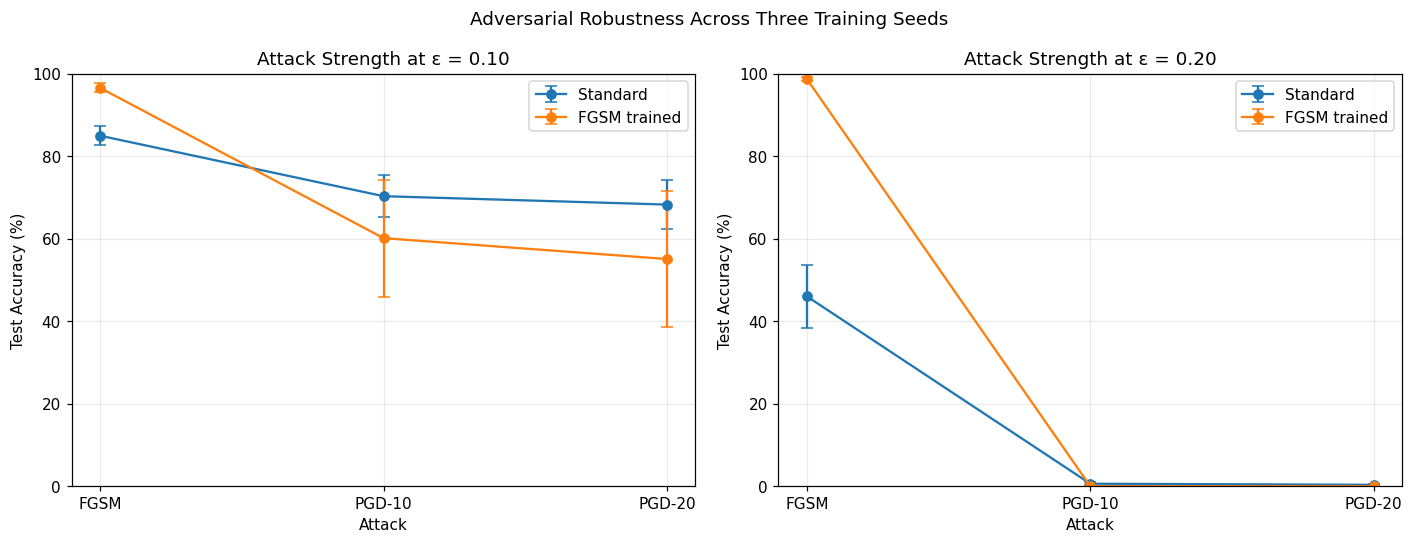

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

attack_order = ["FGSM", "PGD-10", "PGD-20"]

for ax, epsilon in zip(axes, FOLLOWUP_EPSILONS):
  subset = robustness_summary[
    np.isclose(robustness_summary["epsilon"], epsilon)
    & robustness_summary["attack"].isin(attack_order)
  ]

  for name in ("Standard", "FGSM trained"):
    model_rows = (
      subset[subset["model"] == name]
      .set_index("attack")
      .reindex(attack_order)
    )

    ax.errorbar(
      attack_order,
      model_rows["mean_accuracy_pct"],
      yerr=model_rows["std_accuracy_pp"],
      marker="o",
      capsize=4,
      label=name
    )

  ax.set(
    title=f"Attack Strength at ε = {epsilon:.2f}",
    xlabel="Attack",
    ylabel="Test Accuracy (%)",
    ylim=(0, 100)
  )
  ax.legend()

fig.suptitle(
  "Adversarial Robustness Across Three Training Seeds"
)

plt.tight_layout()
plt.savefig(
  OUTPUT_DIR / "attack_strength_comparison.png",
  dpi=160, bbox_inches="tight"
)
plt.show()

The three-seed averages reinforce the differences between FGSM resistance and robustness against iterative adversarial attacks. At $\epsilon=0.20$, the FGSM-trained CNN achieves a mean FGSM accuracy of $98.73\%$, compared with $46.03\%$ for the standard CNN. However, this advantage disappears under PGD-10 and PGD-20, where the FGSM-trained CNN achieves $0.00\%$ accuracy under both configurations.

A similar distinction appears at the smaller perturbation budget of $\epsilon=0.10$. The FGSM-trained CNN maintains a mean FGSM accuracy of $96.57\%$, compared with $84.97\%$ for the standard CNN. Under PGD-20, however, the standard CNN achieves $68.27\%$ accuracy, while the FGSM-trained CNN achieves $55.07\%$. This suggests that FGSM adversarial training does not necessarily improve resistance to stronger attacks, even when the perturbation magnitude is reduced.

The standard deviations also reveal differences in training variability. At $\epsilon=0.10$, the FGSM-trained CNN has a standard deviation of $16.40$ percentage points under PGD-20, compared with $5.98$ percentage points for the standard CNN. This indicates that the FGSM-trained model's performance against PGD varies considerably across the three training seeds, even though its FGSM accuracy remains relatively consistent.

Overall, the results demonstrate that improvements against FGSM are reproducible across training runs, but these improvements do not translate into consistent robustness against iterative PGD attacks. Because only three seeds were evaluated, the reported standard deviations should be interpreted as descriptive measurements of training variability rather than definitive estimates of the broader distribution of model performance.

### Training Dynamics and Robustness Deterioration

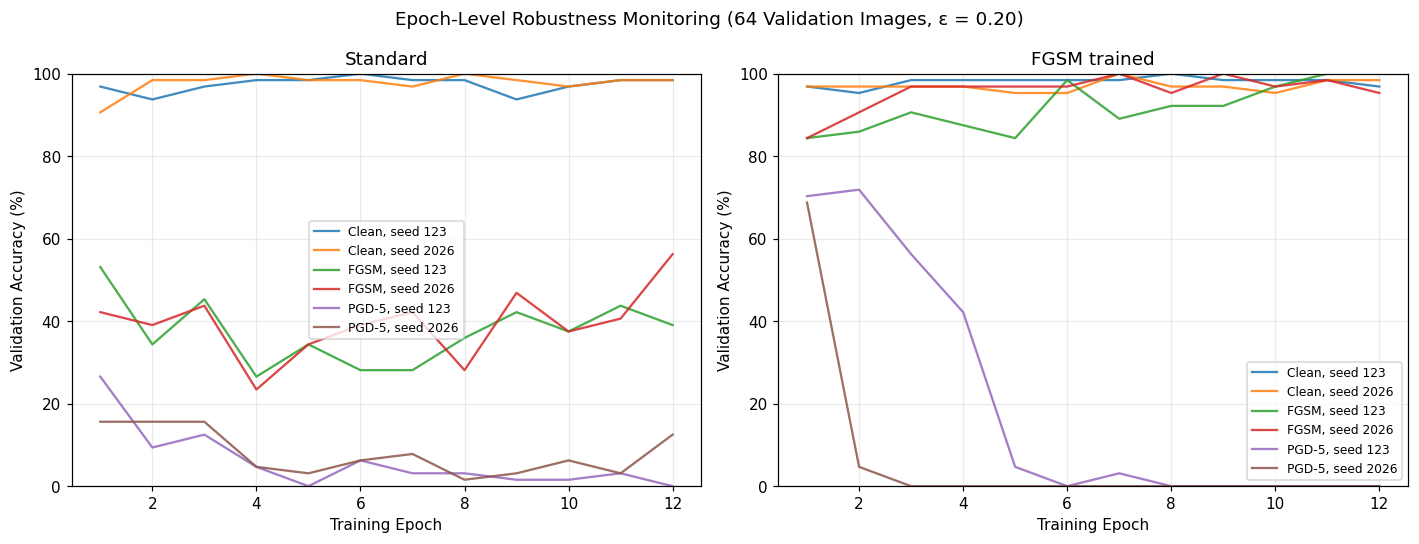

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics = {
  "monitor_clean": "Clean",
  "monitor_fgsm": "FGSM",
  "monitor_pgd": "PGD-5",
}

for ax, name in zip(axes, ("Standard", "FGSM trained")):
  for metric, label in metrics.items():
    for seed in FOLLOWUP_SEEDS[1:]:
      data = monitor_results[
        (monitor_results["seed"] == seed)
        & (monitor_results["model"] == name)
      ]

      ax.plot(
        data["epoch"],
        100 * data[metric],
        label=f"{label}, seed {seed}",
        alpha=0.85
      )

  ax.set(
    title=name,
    xlabel="Training Epoch",
    ylabel="Validation Accuracy (%)",
    ylim=(0, 100)
  )
  ax.legend(fontsize=8)

fig.suptitle(
  "Epoch-Level Robustness Monitoring "
  "(64 Validation Images, ε = 0.20)"
)

plt.tight_layout()
plt.savefig(
  OUTPUT_DIR / "epoch_robustness_monitoring.png",
  dpi=160, bbox_inches="tight"
)
plt.show()

The epoch-level monitoring curves provide additional insight into how adversarial robustness changes during training. Both CNNs generally maintain high accuracy on clean validation images, but their behavior against FGSM and PGD differs considerably.

For the standard CNN, FGSM and PGD-5 accuracy remain substantially below clean accuracy throughout training. This behavior is expected because the model is optimized using clean images without explicitly incorporating adversarial perturbations into its training objective.

The FGSM-trained CNN initially demonstrates improvements against both attacks, but its PGD-5 accuracy deteriorates sharply during training. For seed 123, PGD-5 accuracy decreases from $71.9\%$ at epoch 2 to $0.0\%$ at epoch 6, while FGSM accuracy increases from $85.9%$ to $98.4%$. A similar pattern appears for seed 2026, where PGD-5 accuracy decreases from $68.8\%$ at epoch 1 to $0.0\%$ by epoch 3.

These results are consistent with catastrophic overfitting, a phenomenon in which adversarial robustness against stronger attacks deteriorates during single-step adversarial training, even while accuracy against the training attack remains high. The model appears to develop resistance to FGSM perturbations without maintaining comparable resistance to iterative attacks.

However, these monitoring results are based on a fixed subset of only 64 validation images and two training seeds. Although the observed deterioration is substantial, the experiment does not conclusively identify its underlying mechanism. The results nevertheless provide important evidence that clean accuracy and FGSM accuracy alone may fail to reveal a deterioration in adversarial robustness during training.

### Effect of FGSM Adversarial Training

To quantify the effect of FGSM adversarial training, the final comparison focuses on the difference between the standard CNN and the FGSM-trained CNN under each attack configuration. Since the two models share identical initial weights and training-example ordering within each seed, their results can be compared as matched training runs.

The paired accuracy difference is defined as

$$
\Delta_{\mathrm{accuracy}}
=
\mathrm{Accuracy}_{\mathrm{FGSM-trained}}
-
\mathrm{Accuracy}_{\mathrm{Standard}}.
$$

A Positive value indicates that FGSM adversarial training improves accuracy under the specified attack, while a negative value indicates lower accuracy. These differences are expressed in percentage points to make the effect of adversarial training easier to interpret. 

By comparing the accuracy differences across seeds, perturbation budgets, and attack configurations, we can determine whether FGSM adversarial training provides a consistent advantage or whether its benefits are limited to paricular adversarial attacks.

In [24]:
paired_results = robustness_results.pivot(
  index=["seed", "attack", "epsilon"],
  columns="model",
  values="accuracy"
).reset_index()

paired_results["difference_pp"] = 100 * (
  paired_results["FGSM trained"]
  - paired_results["Standard"]
)

paired_summary = (
  paired_results
  .groupby(["attack", "epsilon"], as_index=False)
  .agg(
    mean_difference_pp=("difference_pp", "mean"),
    std_difference_pp=("difference_pp", "std"),
    min_difference_pp=("difference_pp", "min"),
    max_difference_pp=("difference_pp", "max"),
  )
)

paired_results.to_csv(
  OUTPUT_DIR / "paired_seed_differences.csv",
  index=False
)

paired_summary.to_csv(
  OUTPUT_DIR / "paired_difference_summary.csv",
  index=False
)

display(paired_summary.round(2))

print("\nEvaluation completed.")
print("Models evaluated:", 2 * len(FOLLOWUP_SEEDS))
print("Final PGD restarts:", FOLLOWUP_RESTARTS)
print("Fixed PGD test subset:", len(test_subset))
print("Results saved to:", OUTPUT_DIR)

,attack,epsilon,mean_difference_pp,std_difference_pp,min_difference_pp,max_difference_pp
0,Clean,0.0,-0.03,0.15,-0.2,0.1
1,FGSM,0.1,11.60,3.11,8.9,15.0
2,FGSM,0.2,52.70,8.12,43.8,59.7
3,PGD-10,0.1,-10.17,10.92,-19.6,1.8
4,PGD-10,0.2,-0.60,0.36,-0.9,-0.2
5,PGD-20,0.1,-13.20,12.26,-23.4,0.4
6,PGD-20,0.2,-0.33,0.25,-0.6,-0.1



Evaluation completed.
Models evaluated: 6
Final PGD restarts: 3
Fixed PGD test subset: 1000
Results saved to: /kaggle/working/report3_followup


The paired accuracy differences provide a direct comparison of the effects of FGSM adversarial training under each attack configuration. On clean test images, the mean accuracy difference between the two CNNs is only $-0.03$ percentage points, indicating that FGSM adversarial training has little effect on clean classification performance under the tested configuration.

Under FGSM, the advantages of adversarial training are considerably larger. At $\epsilon=0.10$, the FGSM-trained CNN achieves an average improvement of $11.60$ percentage points, increasing to $52.70$ percentage points at $\epsilon=0.20$. These positive differences are observed across all three seeds, demonstrating that the improvement in FGSM accuracy is not limited to a particular model initialization.

The differences become less favorable under PGD. At $\epsilon=0.10$, the FGSM-trained CNN achieves an average accuracy difference of $-10.17$ percentage points under PGD-10 and $-13.20$ percentage points under PGD-20. However, the individual paired results vary across seeds, with seed 2026 showing a slight positive difference under both PGD configurations. Consequently, the negative mean differences should not be interpreted as a universal disadvantage of FGSM adversarial training.

At $\epsilon=0.20$, the mean differences under PGD-10 and PGD-20 are only $-0.60$ and $-0.33$ percentage points, respectively. These small differences occur because both models have almost no remaining accuracy under the stronger attacks, rather than because their adversarial robustness is equivalent in a broader sense.

Overall, the paired comparisons reinforce the central finding that FGSM adversarial training substantially improves resistance to FGSM but does not provide a corresponding advantage against iterative PGD attacks.


## Discussion

Our central research question was whether FGSM adversarial training improves a CNN's resistance to single-step adversarial attacks and, more importantly, whether that improvement extends to stronger iterative attacks such as PGD.

The experimental results reveal a clear distinction between **attack-specific resistance and broader adversarial robustness**.

### Effect of FGSM Adversarial Training on FGSM Accuracy

After FGSM adversarial training, the model’s accuracy under FGSM rises to near its clean level. On the complete MNIST test set, the FGSM-trained CNN has $98.97\%$ accuracy under FGSM at $\epsilon = 0.20$, compared with $44.43\%$ for the standard CNN, a difference of 54.54 percentage points. Both models also keep about $99\%$ clean test accuracy, so this change did not require a large loss of clean accuracy under our configuration.

The FGSM-trained model also keeps high FGSM accuracy beyond its training budget: $93.55\%$ at $\epsilon = 0.30$, versus $21.44\%$ for the standard CNN. However, its FGSM accuracy is non-monotonic in $\epsilon$ and slightly exceeds its clean accuracy at $\epsilon=0.20$, which a true worst-case accuracy cannot do (it is bounded above by clean accuracy and non-increasing in $\epsilon$). These values therefore describe how weak FGSM is against this model, not how robust the model is.

### Why FGSM Resistance Does Not Imply PGD Robustness

The PGD experiment exposes the principal limitation of our adversarial training strategy. At $\epsilon = 0.20$, the FGSM-trained CNN achieves $99.2\%$ accuracy against FGSM on the matched 1,000-image test subset, but its accuracy falls to **0.0% under PGD-10**.Meanwhile, the standard CNN achieves $44.6\%$ FGSM accuracy and $1.4\%$ PGD accuracy on the same subset.

These findings demonstrate that the substantial improvement against FGSM does not transfer to the iterative PGD attack. In fact, the FGSM-trained CNN performs worse than the standard CNN under PGD at several perturbation magnitudes.

One possible explanation involves the limitations of single-step adversarial training. FGSM constructs adversarial examples using a first-order approximation of the loss around the original input. Consequently, it relies on local gradient information to determine a single perturbation direction. PGD instead performs repeated gradient-based updates, allowing it to explore multiple points within the permitted perturbation region. A model trained to resist one-step perturbations may therefore remain vulnerable to adversarial examples that require a more extensive search to identify.

The substantial discrepancy between FGSM and PGD accuracy is consistent with several potential phenomena, including gradient masking, catastrophic overfitting, and label leaking. In particular, the epoch-level monitoring results provide additional evidence consistent with catastrophic overfitting, as the FGSM-trained CNN experiences a sharp deterioration in PGD-5 accuracy while maintaining high accuracy against FGSM.

Gradient masking can create an appearance of adversarial robustness when an attack fails to identify vulnerabilities that stronger optimization methods can exploit. Label leaking may also occur when adversarial perturbations generated using the true class label introduce patterns that the model learns to recognize. Although these mechanisms provide possible explanations for the observed behavior, the current experiments do not establish which mechanisms are responsible.

One asymmetry is worth stating: a successful attack is a certificate. Every adversarial example found by PGD is a valid input inside the permitted region (the implementation checks the $L_\infty$ and pixel-range constraints) that the model misclassifies, so PGD’s $0.0\%$ accuracy at $\epsilon=0.20$ shows that, on these 1,000 images, the model is not robust at that budget. High accuracy under FGSM carries no such guarantee.

However, our experiment does not conclusively establish either mechanism. We have observed a substantial discrepancy between FGSM and PGD performance, but identifying its precise cause would require additional experiments.

### Implications for Evaluating Adversarial Robustness

An important lesson from this investigation is that evaluating robustness using only the attack employed during training can produce an incomplete picture of model reliability. If we had evaluated the FGSM-trained CNN exclusively against FGSM, we might have concluded that adversarial training provided strong protection against input perturbations. The PGD results substantially change that interpretation.

This distinction also highlights the difference between empirical adversarial accuracy and worst-case robustness. Ideally, adversarial robustness would require a model to classify inputs correctly throughout a specified perturbation region. In practice, attacks such as FGSM and PGD search for examples that violate this condition, but a finite search cannot guarantee that all possible adversarial inputs have been identified.

Our results therefore support conclusions about the effectiveness of the tested attacks and training procedures, rather than establishing formal robustness guarantees.

## Experimental Limitations

Although the findings demonstrate a substantial difference between FGSM and PGD resistance, several limitations should be acknowledged.

### Model and Dataset Scope

The experiment uses a relatively compact CNN trained on MNIST, a dataset consisting of low-resolution grayscale handwritten digits. This provides a computationally accessible setting for investigating adversarial attacks, but the results may not generalize directly to larger architectures or more complex datasets such as CIFAR-10 or ImageNet.

The relative simplicity of MNIST may also influence how quickly the networks achieve high clean accuracy and how they respond to adversarial perturbations.

### Training Duration and Model Selection

Both models were trained for 12 epochs using the same optimization schedule, and their final-epoch parameters were evaluated without checkpoint selection. Although both achieved high clean validation accuracy, this does not establish that their adversarial robustness had converged. In particular, clean validation performance alone cannot reveal whether the FGSM-trained CNN experienced a deterioration in PGD robustness during training.

The epoch-level monitoring results demonstrate that PGD robustness can deteriorate substantially during FGSM adversarial training, even when clean and FGSM accuracy remain high. However, intermediate adversarial accuracy was monitored only for seeds 123 and 2026 using 64 validation images. These measurements provide evidence of changing robustness during training but are not sufficient to characterize its behavior across the complete validation set or a larger collection of random seeds.

Furthermore, the standard CNN's training metrics were calculated on clean images, while the FGSM-trained CNN's metrics were calculated using mixed clean and adversarial inputs. Their training losses and accuracies therefore do not represent directly equivalent measurements of clean-image performance.

### Attack Configuration and Evaluation Size

The complete FGSM evaluation uses all 10,000 MNIST test images, whereas the matched FGSM–PGD comparison uses a fixed random subset of 1,000 images. Although the matched subset ensures consistent comparisons between attacks and models, its smaller size introduces sampling uncertainty.

The PGD evaluation uses 10 and 20 optimization steps with three random restarts per image. These configurations provide a more extensive adversarial search than the initial single-start PGD experiment. The multi-restart implementation also prioritizes successfully misclassified candidates, reducing the possibility that a high-loss but correctly classified image is selected over a successful adversarial example.

Nevertheless, the evaluation remains limited to finite attack budgets and the selected PGD configurations. Other adversarial attacks, additional optimization steps, or larger numbers of restarts could reveal further vulnerabilities. The reported accuracies therefore represent empirical attack outcomes rather than certified worst-case robustness guarantees.

### Diagnosing the FGSM–PGD Discrepancy

One of the most significant observations from this experiment is the substantial difference between the FGSM-trained CNN's performance against FGSM and PGD. Although the model achieves nearly perfect accuracy against the single-step attack, its accuracy decreases sharply when evaluated using iterative PGD, even under the same perturbation budget.

The additional experiments provide further evidence that this discrepancy is not limited to one training run or a particular PGD configuration. Across three random seeds, the FGSM-trained CNN achieves a mean FGSM accuracy of 98.73% at $\epsilon=0.20$, while both PGD-10 and PGD-20 with three random restarts reduce its accuracy to 0.00%. Furthermore, the epoch-level monitoring results reveal that PGD-5 accuracy deteriorates substantially during FGSM adversarial training, despite clean and FGSM accuracy remaining relatively high.

This behavior is consistent with catastrophic overfitting, where a model trained using single-step adversarial examples loses resistance to stronger iterative attacks while maintaining apparent robustness against the training attack. Another possible explanation involves gradient masking, where the model's learned loss landscape makes certain gradient-based attacks less effective without necessarily reducing its underlying adversarial vulnerability. Label leaking may also contribute if perturbations generated using true labels introduce patterns that the model learns to exploit.

However, these mechanisms cannot be conclusively identified from accuracy measurements alone. The observed decline in PGD robustness supports the possibility of catastrophic overfitting, but additional analysis of the loss landscape, gradient behavior, and alternative adversarial attacks would be necessary to determine the underlying causes.

Overall, the discrepancy demonstrates that high accuracy against FGSM does not necessarily indicate meaningful robustness against stronger adversarial optimization. The repeated training runs and multi-restart PGD evaluations reinforce the importance of testing adversarially trained neural networks using attacks beyond those employed during training.

## Conclusion

This experiment investigated whether FGSM adversarial training improves the robustness of a convolutional neural network and whether those improvements extend to stronger iterative attacks such as Projected Gradient Descent.

The results demonstrate that **FGSM adversarial training substantially improves accuracy against FGSM perturbations** while preserving high clean classification accuracy. On the complete MNIST test set, the FGSM-trained CNN achieved $98.97\%$ accuracy under FGSM at $\epsilon=0.20$, compared with $44.43\%$ for the standard CNN.

However, the PGD evaluations reveal a fundamentally different outcome. Across three independent training seeds, the FGSM-trained CNN maintained a mean FGSM accuracy of $98.73\%$ at $\epsilon=0.20$ on the fixed 1,000-image test subset, while both PGD-10 and PGD-20 with three random restarts reduced its accuracy to $0.00\%$. These results demonstrate that **the substantial improvement against FGSM does not translate into comparable resistance to iterative adversarial attacks**.

The training-monitoring experiments provide additional insight into this discrepancy. For both monitored seeds, PGD-5 accuracy deteriorated sharply during FGSM adversarial training, even as clean and FGSM accuracy remained relatively high. This behavior is **consistent with catastrophic overfitting**, although the precise mechanism responsible for the deterioration remains unresolved.

Together, these findings highlight an important distinction between resistance to a particular adversarial attack and broader adversarial robustness. **High accuracy against the attack used during training does not guarantee that a model can withstand more extensive adversarial optimization**.

While the experiments strengthen this conclusion through repeated training runs and multi-restart PGD evaluations, the results remain limited to the tested CNN architecture, MNIST dataset, and attack configurations. Further work could compare FGSM and PGD-based adversarial training, investigate alternative attack methods, and examine the mechanisms underlying the observed deterioration in iterative-attack robustness.

Ultimately, this investigation demonstrates why adversarially trained neural networks should be evaluated using attacks that meaningfully challenge their learned defenses rather than relying exclusively on the attack used during training.

### References
This notebook and its experiments were developed based on the adversarial attack methods, training methodology, and discussion of adversarial robustness of these research papers.

Andriushchenko, Maksym, and Nicolas Flammarion. "Understanding and Improving Fast Adversarial Training." *Advances in Neural Information Processing Systems*, vol. 33, 2020. https://arxiv.org/abs/2007.02617.

Athalye, Anish, et al. "Obfuscated Gradients Give a False Sense of Security: Circumventing Defenses to Adversarial Examples." *Proceedings of the 35th International Conference on Machine Learning*, vol. 80, 2018, pp. 274–283. https://arxiv.org/abs/1802.00420.

Goodfellow, Ian J., et al. "Explaining and Harnessing Adversarial Examples." *International Conference on Learning Representations (ICLR)*, 2015. https://arxiv.org/abs/1412.6572.

Kurakin, Alexey, et al. "Adversarial Machine Learning at Scale." *International Conference on Learning Representations (ICLR)*, 2017. https://arxiv.org/abs/1611.01236.

Madry, Aleksander, et al. "Towards Deep Learning Models Resistant to Adversarial Attacks." *International Conference on Learning Representations (ICLR)*, 2018. https://arxiv.org/abs/1706.06083.

Wong, Eric, et al. "Fast Is Better than Free: Revisiting Adversarial Training." *International Conference on Learning Representations (ICLR)*, 2020. https://arxiv.org/abs/2001.03994.
